# 전체 데이터 30회 학습 · 최종 테스트 결과

**학습 26,031장 · 검증 5,581장 · 테스트 5,581장 · 30/30회 완료**

| 테스트 지표 | 결과 |
|---|---:|
| mAP50 | 0.630 |
| mAP50–95 | 0.413 |
| Precision | 0.704 |
| Recall | 0.582 |

| 클래스 | 테스트 AP50 |
|---|---:|
| 사람 | 0.551 |
| 화재 | 0.804 |
| 연기 | 0.671 |
| 문 | 0.815 |
| 계단 | 0.308 |

**보완 우선순위:** 계단 데이터 보강 → 사람 미탐 분석 → 유사 장면 누수 점검 → Jetson Orin NX·D435i 실제 탐지와 깊이 지도 통합 검증. 계단 테스트 객체는 31개로 추가 검증이 필요합니다.

**결과 저장 위치:** `MyDrive/disaster_drone_backup/full_training/20260914_060759/`

재개 셀의 `FINAL SAVED` 완료 로그 확인. 최종 결과 파일: `best.pt`, `last.pt`, `results.csv`, `metrics.json`, `summary_chart.png`, `predictions.jpg`, `improvements.txt`.

위 수치는 최신 전체 학습 테스트 로그의 소수점 3자리 값입니다. 아래 1,143장·10회 요약과 과거 mAP50 0.636은 이전 실험 기록입니다. 이번 결과는 공개 RGB 데이터 테스트이며 실제 Jetson 속도, D435i 맵핑 및 자율비행 검증 결과가 아닙니다. 장비: Jetson Orin NX + D435i, F450은 전시용.

# 공경진 · 재난 정찰 드론 Colab
Orin Nano Super / D435i / Pixhawk 6C / F450

1~4단계는 데이터 없이 실행됩니다. 실제 5종 학습은 **라벨이 포함된 데이터셋**을 연결한 뒤 실행합니다. Colab에서는 로컬 USB 카메라·비행 제어기를 직접 사용할 수 없습니다. 합성 지도는 성능 결과가 아닙니다. TensorRT engine은 Jetson에서 변환합니다.


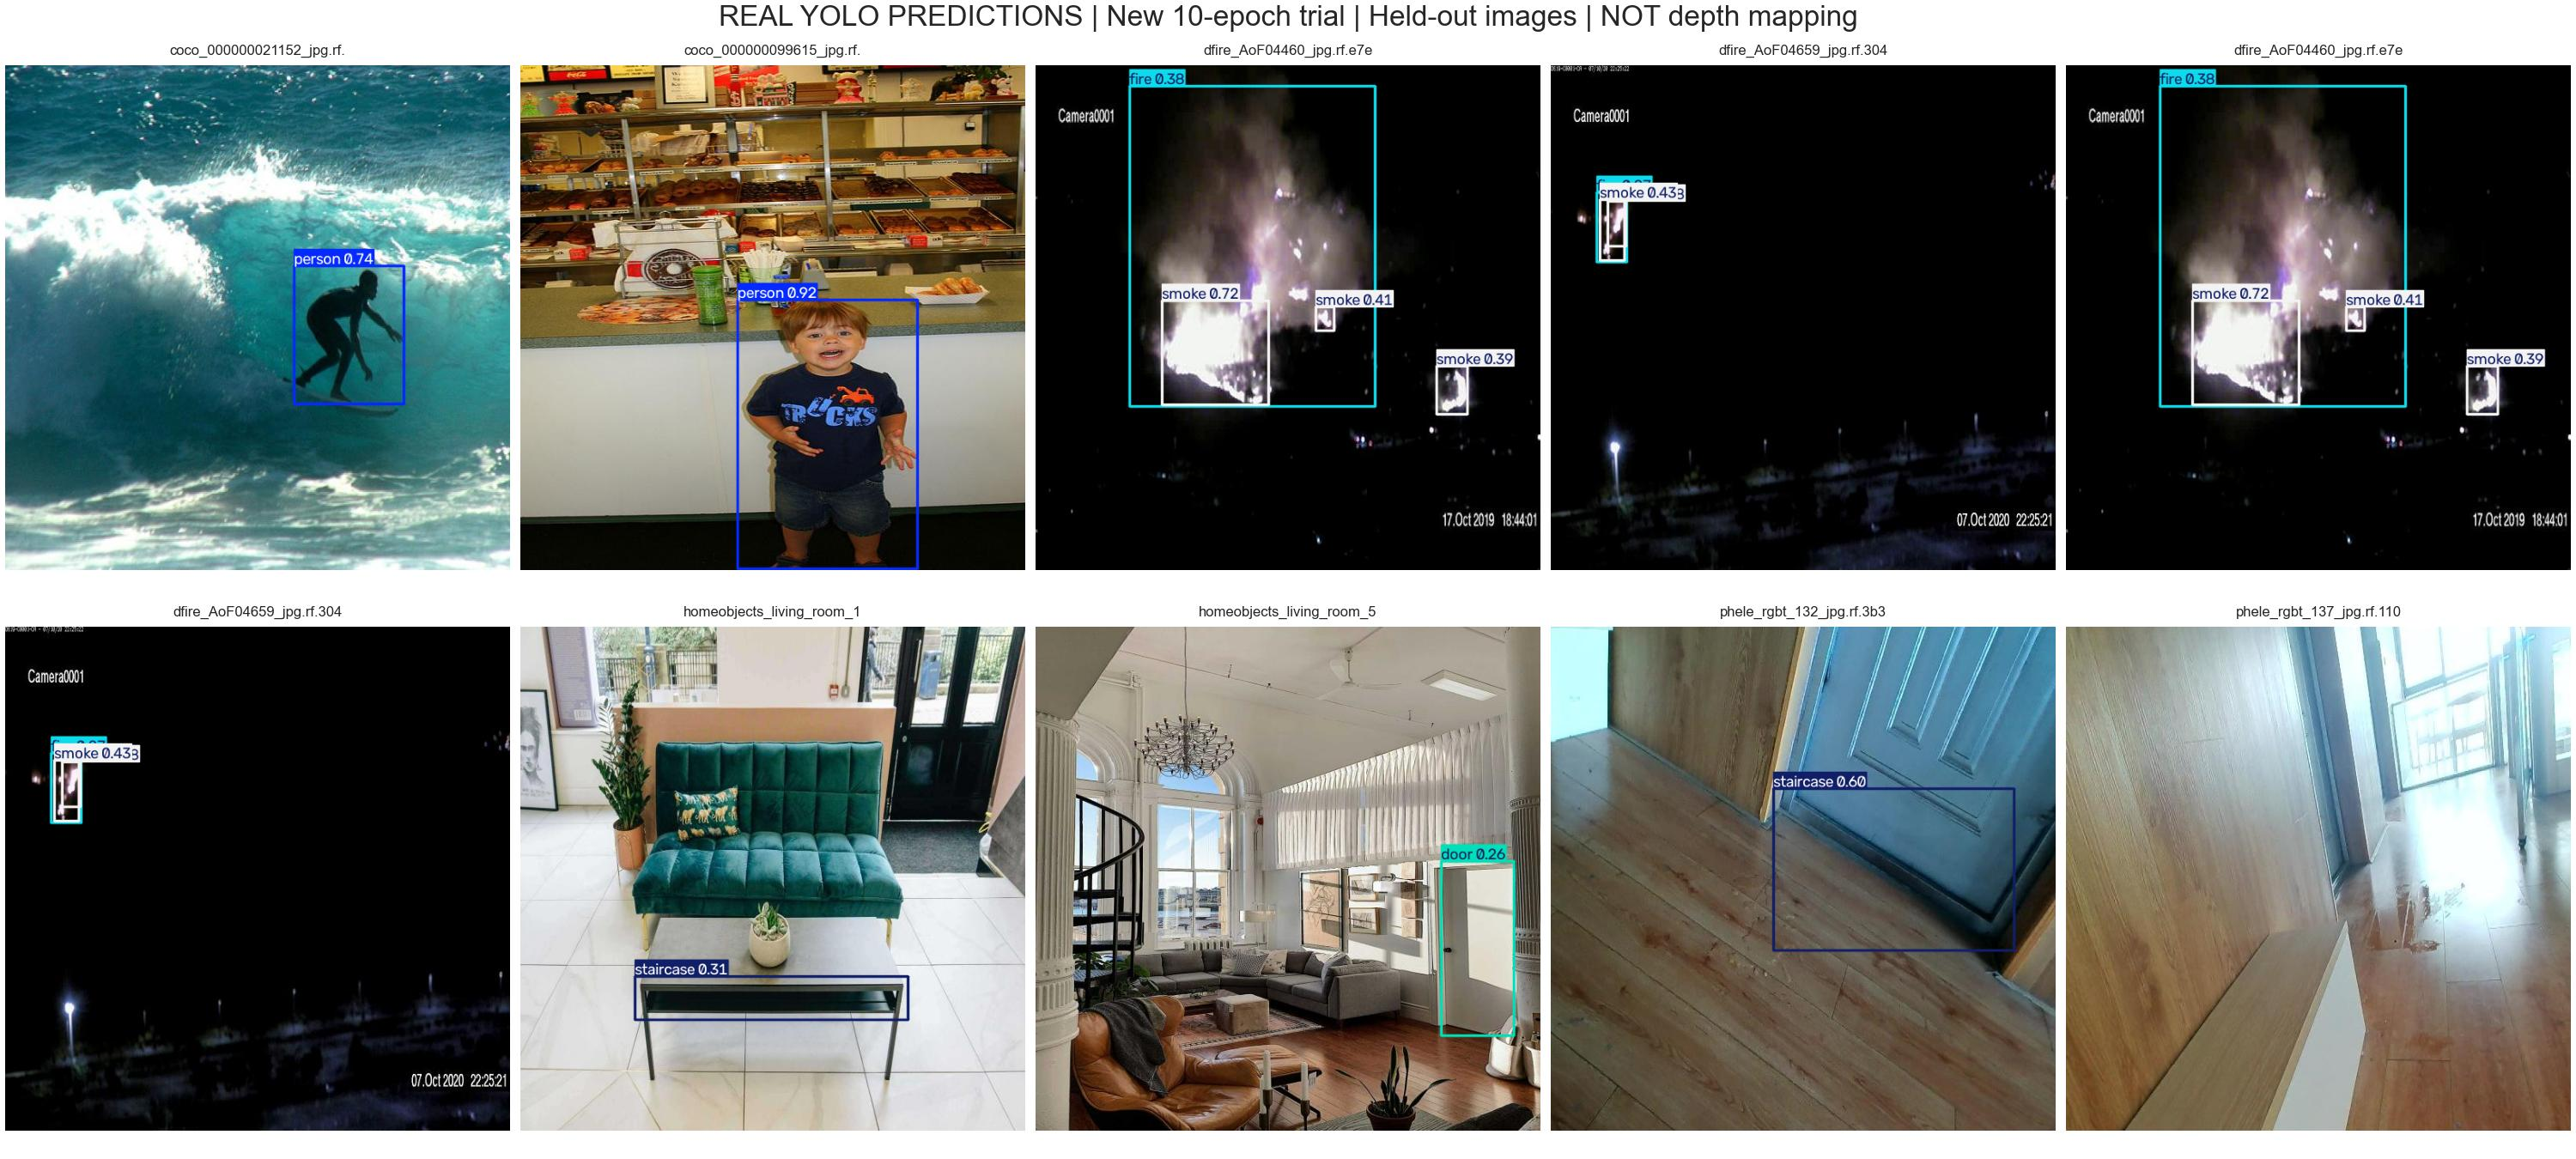

In [ ]:
# RESULT OVERVIEW — load actual saved artifacts, not example numbers
from pathlib import Path
from IPython.display import display, HTML
import pandas as pd, base64, html
folder=Path('/content/drive/MyDrive/disaster_drone_backup/visual_trial')
if not (folder/'results.csv').is_file():
    display(HTML('<h2>Drive 연결이 필요합니다</h2><p>아래 Drive 연결 셀 실행 후 이 요약을 다시 실행하세요.</p>'))
else:
    history=pd.read_csv(folder/'results.csv');history.columns=history.columns.str.strip()
    score=0.1*history['metrics/mAP50(B)']+0.9*history['metrics/mAP50-95(B)'] if False else history['metrics/mAP50-95(B)']
    row=history.loc[score.idxmax()]
    picture=folder/'actual_predictions.jpg'
    image_html=('<img style="width:100%;border-radius:12px" src="data:image/jpeg;base64,'+base64.b64encode(picture.read_bytes()).decode()+'">') if picture.is_file() else '<p>탐지 사진 생성 대기</p>'
    cards=''.join('<div class="metric"><small>'+label+'</small><b>'+value+'</b></div>' for label,value in [('학습 이미지','1,143장'),('학습 완료',str(len(history))+'회'),('검증 이미지','233장'),('검증 mAP50',format(row['metrics/mAP50(B)'],'.3f'))])
    display(HTML('''<style>.overview{font-family:Arial,sans-serif;background:#102138;color:#fff;padding:24px;border-radius:16px}.overview h1{font-size:28px;margin:0 0 12px}.metrics{display:flex;gap:12px;flex-wrap:wrap;margin:20px 0}.metric{background:#213a57;padding:18px;min-width:160px;border-radius:10px}.metric small{display:block;color:#c3d3e5}.metric b{font-size:30px}.notice{background:#fff0cb;color:#45320a;padding:12px;border-radius:8px}.overview p{line-height:1.7}</style><section class="overview"><h1>재난 5종 AI · 실제 재학습 결과</h1><p>2026-09-14 · Colab Tesla T4 · YOLOv8n · 입력 640×640</p><div class="notice">이번 결과는 전체 학습 데이터의 약 4.4%를 사용한 10회 시연용 학습입니다. 전체 데이터 최종 성능이나 Jetson 실측 성능이 아닙니다.</div><div class="metrics">'''+cards+'''</div><h2>실제 테스트 이미지 탐지</h2><p>학습에 넣지 않은 이미지에 새 모델을 적용했습니다. 아래 사진은 2D 맵핑 결과가 아닙니다.</p>'''+image_html+'''<h2>저장된 파일</h2><p>내 드라이브 → disaster_drone_backup → visual_trial<br>best.pt · last.pt · results.csv · actual_predictions.jpg · predictions.json</p><p>표시 성능: 저장된 학습 로그에서 mAP50–95가 가장 높은 회차의 검증 mAP50. 이전 9월 13일 모델의 테스트 mAP50 0.636과 별도입니다.</p></section>'''))


In [ ]:
# FULL DATA TRAINING — 30 epochs, persistent backups and final test
from pathlib import Path
import os,sys,json,shutil,hashlib,time,yaml
import torch
from ultralytics import YOLO
from IPython.display import display,HTML,Image,clear_output
assert torch.cuda.is_available(), 'GPU required'
assert Path('/content/drive/MyDrive').is_dir(), 'Mount Drive first'
source=Path('/content/disaster_source'); full=Path('/content/disaster_full_v2')
assert (source/'data.yaml').is_file(), 'Restore dataset ZIP first'
run_id=time.strftime('%Y%m%d_%H%M%S')
saved=Path('/content/drive/MyDrive/disaster_drone_backup/full_training')/run_id
saved.mkdir(parents=True,exist_ok=False)
status_display=display(HTML('<h1>전체 데이터 학습 준비 중</h1><p>라벨 변환·중복 검사 후 최대 30회 학습합니다.</p>'),display_id=True)
def update_status(title,detail):
    import html
    status_display.update(HTML('<section style="padding:24px;background:#102138;color:white;border-radius:12px"><h1>'+html.escape(title)+'</h1><p>'+html.escape(detail)+'</p><p>Drive: '+html.escape(str(saved))+'</p></section>'))
def digest(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''): h.update(b)
    return h.hexdigest()
def backup_file(src,dst):
    src,dst=Path(src),Path(dst); tmp=dst.with_name(dst.name+'.partial')
    shutil.copy2(src,tmp)
    assert digest(src)==digest(tmp),'Backup checksum mismatch'
    tmp.replace(dst)
classes=['person','fire','smoke','door','staircase']
cfg=yaml.safe_load((source/'data.yaml').read_text());names=cfg['names'];names=dict(enumerate(names)) if isinstance(names,list) else names
remap={int(i):classes.index('staircase' if n=='stairs' else n) for i,n in names.items() if n in classes or n=='stairs'}
assert len(remap)==5
# Pixel-exact duplicates: prioritize test, then validation, then training.
from PIL import Image as PILImage
seen=set();audit={};duplicates=0
full=full/run_id
for split in ['test','valid','train']:
    image_out=full/split/'images';label_out=full/split/'labels'
    image_out.mkdir(parents=True);label_out.mkdir(parents=True)
    count=0;objects=[0]*5
    for image in sorted((source/split/'images').iterdir()):
        if image.suffix.lower() not in ['.jpg','.jpeg','.png','.bmp','.webp']: continue
        label=source/split/'labels'/(image.stem+'.txt')
        assert label.is_file(),str(label)
        with PILImage.open(image) as im:
            im=im.convert('RGB');key=hashlib.sha256(str(im.size).encode()+im.tobytes()).digest()
        if key in seen: duplicates+=1;continue
        seen.add(key);rows=[]
        for row in label.read_text().splitlines():
            fields=row.split()
            if not fields: continue
            assert len(fields)==5,str(label)
            old=int(fields[0]);vals=list(map(float,fields[1:]))
            assert all(0<=v<=1 for v in vals) and vals[2]>0 and vals[3]>0,str(label)
            if old in remap:
                new=remap[old];rows.append(str(new)+' '+' '.join(fields[1:]));objects[new]+=1
        try: os.link(image,image_out/image.name)
        except OSError: shutil.copy2(image,image_out/image.name)
        (label_out/label.name).write_text('\n'.join(rows)+'\n' if rows else '')
        count+=1
    audit[split]={'images':count,'objects':dict(zip(classes,objects))}
    print('DATA READY',split,audit[split],flush=True)
(full/'data.yaml').write_text(yaml.safe_dump({'path':str(full),'train':'train/images','val':'valid/images','test':'test/images','names':classes}))
(saved/'audit.json').write_text(json.dumps({'splits':audit,'pixel_duplicates_removed':duplicates,'source':'https://universe.roboflow.com/zeka-s-workspace/indoor-elder-objection/dataset/3'},indent=2))
backup_file(full/'data.yaml',saved/'data.yaml')
# Start fresh: earlier quick-model validation selection used a different split audit.
model=YOLO('yolov8n.pt')
started=time.time()
def checkpoint(t):
    for item in [t.last,t.best,t.csv]:
        if Path(item).is_file(): backup_file(item,saved/Path(item).name)
    epoch=t.epoch+1;remaining=(time.time()-started)/epoch*(30-epoch)/60
    (saved/'status.json').write_text(json.dumps({'epoch':epoch,'max_epochs':30,'estimated_remaining_minutes':remaining,'complete':False}))
    update_status('전체 데이터 학습 '+str(epoch)+'/30회 완료','모델 Drive 검증 저장 완료 · 남은 학습 예상 '+str(round(remaining))+'분 (평가 시간 별도)')
model.add_callback('on_model_save',checkpoint)
update_status('전체 데이터 GPU 학습 중',str(audit['train']['images'])+'장 · 최대 30회 · Tesla T4')
model.train(data=str(full/'data.yaml'),epochs=30,imgsz=640,batch=16,device=0,workers=2,seed=42,patience=30,close_mosaic=5,save=True,plots=True,project='/content/full_training',name=run_id)
checkpoint(model.trainer)
update_status('전체 학습 완료 · 독립 테스트 평가 중','저장된 best.pt로 test 분할을 평가합니다.')
best=YOLO(str(saved/'best.pt'))
metrics=best.val(data=str(full/'data.yaml'),split='test',imgsz=640,batch=16,device=0,workers=2,plots=True,project='/content/full_evaluation',name=run_id)
report={'split':'test','GPU':torch.cuda.get_device_name(0),'metrics':{k:float(v) for k,v in metrics.results_dict.items()},'per_class':{},'speed_ms':metrics.speed,'audit':audit}
for i,c in enumerate(metrics.box.ap_class_index):
    p,r,ap50,ap=metrics.box.class_result(i)
    report['per_class'][best.names[int(c)]]={'precision':float(p),'recall':float(r),'AP50':float(ap50),'AP50_95':float(ap)}
(saved/'metrics.json').write_text(json.dumps(report,indent=2))
shutil.copytree(metrics.save_dir,saved/'test_evaluation',dirs_exist_ok=True)
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(13,5),layout='constrained')
cn=list(report['per_class']);v=[report['per_class'][n]['AP50'] for n in cn]
b=axs[0].barh(cn,v);axs[0].set_xlim(0,1);axs[0].bar_label(b,fmt='%.3f');axs[0].set_title('Full training: TEST AP50')
import pandas as pd
hist=pd.read_csv(saved/'results.csv');hist.columns=hist.columns.str.strip();axs[1].plot(hist['epoch'],hist['metrics/mAP50(B)'],label='Validation mAP50');axs[1].legend();axs[1].set_xlabel('Epoch')
fig.savefig(saved/'summary_chart.png',dpi=160);plt.close(fig)
testimgs=sorted((full/'test/images').iterdir());chosen=[]
for c in range(5):
    candidates=[p for p in testimgs if any(int(r.split()[0])==c for r in (full/'test/labels'/(p.stem+'.txt')).read_text().splitlines() if r.strip())]
    chosen.extend(candidates[:2])
fig,axs=plt.subplots(2,5,figsize=(18,8),layout='constrained')
for ax,p in zip(axs.flat,chosen):
    pred=best.predict(str(p),device=0,conf=.25,verbose=False)[0];ax.imshow(pred.plot()[...,::-1]);ax.axis('off')
fig.suptitle('Full-data model predictions on held-out images');fig.savefig(saved/'predictions.jpg',dpi=150);plt.close(fig)
weak=sorted(report['per_class'],key=lambda n:report['per_class'][n]['AP50'])
notes='보완 우선 클래스: '+', '.join(weak[:2])+' · 계단 데이터 추가 수집 · 유사 장면 누수 점검 · 실제 D435i/Jetson 검증 · 탐지와 깊이 지도의 통합 실측 필요'
(saved/'improvements.txt').write_text(notes,encoding='utf-8')
(saved/'status.json').write_text(json.dumps({'complete':True,'epochs':len(hist)}))
update_status('전체 데이터 학습·테스트 완료','Test mAP50 '+format(metrics.box.map50,'.3f')+' · '+notes)
display(Image(filename=str(saved/'summary_chart.png')));display(Image(filename=str(saved/'predictions.jpg')))
print('FINAL SAVED',saved,flush=True)


DATA READY test {'images': 5581, 'objects': {'person': 3441, 'fire': 1768, 'smoke': 2245, 'door': 254, 'staircase': 31}}
DATA READY valid {'images': 5581, 'objects': {'person': 3049, 'fire': 1768, 'smoke': 2112, 'door': 257, 'staircase': 38}}
DATA READY train {'images': 26031, 'objects': {'person': 14104, 'fire': 8330, 'smoke': 10325, 'door': 1251, 'staircase': 175}}
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/disaster_full_v2/20260914_060759/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None,

In [ ]:
# RECOVERY CHECK — inspect before resuming
from pathlib import Path
import subprocess, json
print(subprocess.getoutput('nvidia-smi'))
print('LOCAL:', [p.name for p in Path('/content').iterdir()])
from google.colab import drive
drive.mount('/content/drive')
root=Path('/content/drive/MyDrive/disaster_drone_backup/full_training')
for p in sorted(root.glob('*')):
 print('RUN', p.name)
 if (p/'status.json').exists(): print((p/'status.json').read_text())
 print([(q.name,q.stat().st_size) for q in p.glob('*') if q.is_file()])

Mon Sep 14 09:11:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# RECOVERY SETUP — install same training version, verify saved epoch
%pip -q install ultralytics==8.4.150
from pathlib import Path
import torch, json
saved=Path('/content/drive/MyDrive/disaster_drone_backup/full_training/20260914_060759')
assert (saved/'last.pt').is_file(), 'Drive checkpoint not accessible; do not start fresh'
ckpt=torch.load(saved/'last.pt',map_location='cpu',weights_only=False)
print('RECOVERABLE COMPLETED EPOCHS:',ckpt['epoch']+1)
print('OPTIMIZER PRESENT:',ckpt.get('optimizer') is not None)
print('DATA CONFIG:',ckpt['train_args']['data'])
print('TRAIN ARGS:', {k:ckpt['train_args'].get(k) for k in ['epochs','optimizer','batch','imgsz','save_dir']})
print('BACKUP FILES:',[(p.name,p.stat().st_size) for p in saved.iterdir() if p.is_file()])
del ckpt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 7.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
RECOVERABLE COMPLETED EPOCHS: 21
OPTIMIZER PRESENT: True
DATA CONFIG: /content/disaster_full_v2/20260914_060759/data.yaml
TRAIN ARGS: {'epochs': 30, 'optimizer': 'auto', 'batch': 16, 'imgsz': 640, 'save_dir': '/content/full_training/20260914_060759'}
BACKUP FILES: [('audit.json', 708), ('data.yaml', 154), ('status.json', 100), ('results.csv', 3503), ('best.pt', 18372549), ('last.pt', 18372549)]


RESTORING DATASET FROM DRIVE 1774425375 bytes
DATASET ZIP RESTORED AND CRC VERIFIED
RESUMING AFTER EPOCH 21


DATA READY test {'images': 5581, 'objects': {'person': 3441, 'fire': 1768, 'smoke': 2245, 'door': 254, 'staircase': 31}}
DATA READY valid {'images': 5581, 'objects': {'person': 3049, 'fire': 1768, 'smoke': 2112, 'door': 257, 'staircase': 38}}
DATA READY train {'images': 26031, 'objects': {'person': 14104, 'fire': 8330, 'smoke': 10325, 'door': 1251, 'staircase': 175}}
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/disaster_full_v2/20260914_060759/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None,

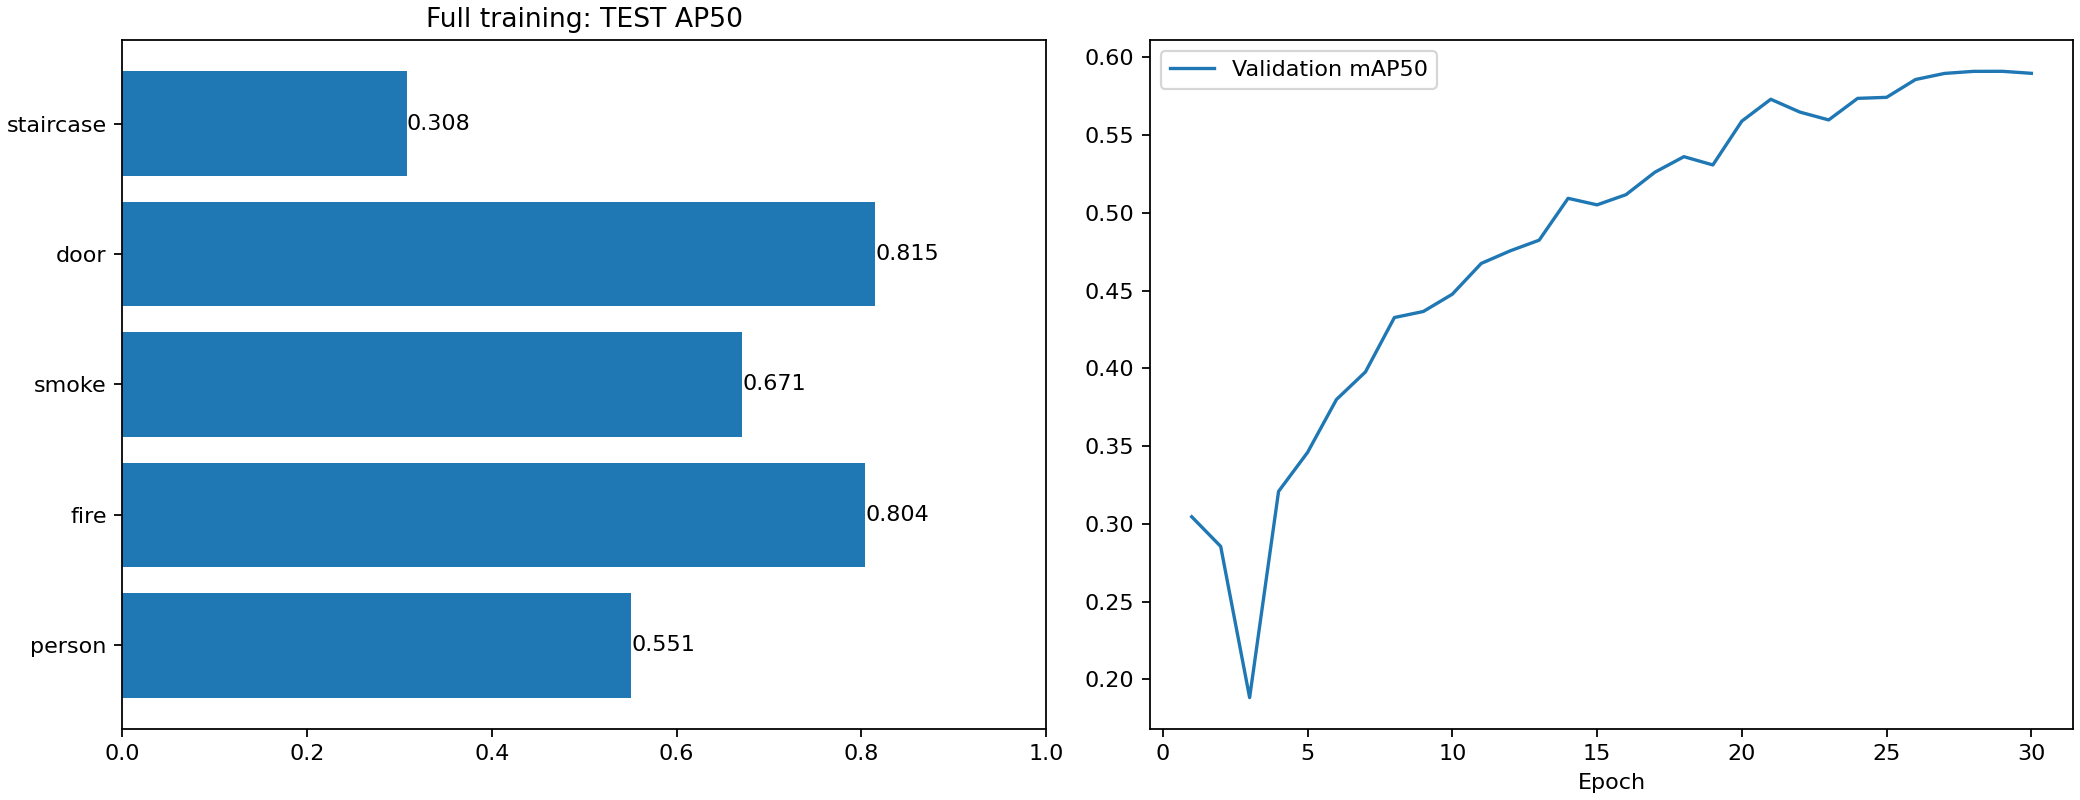

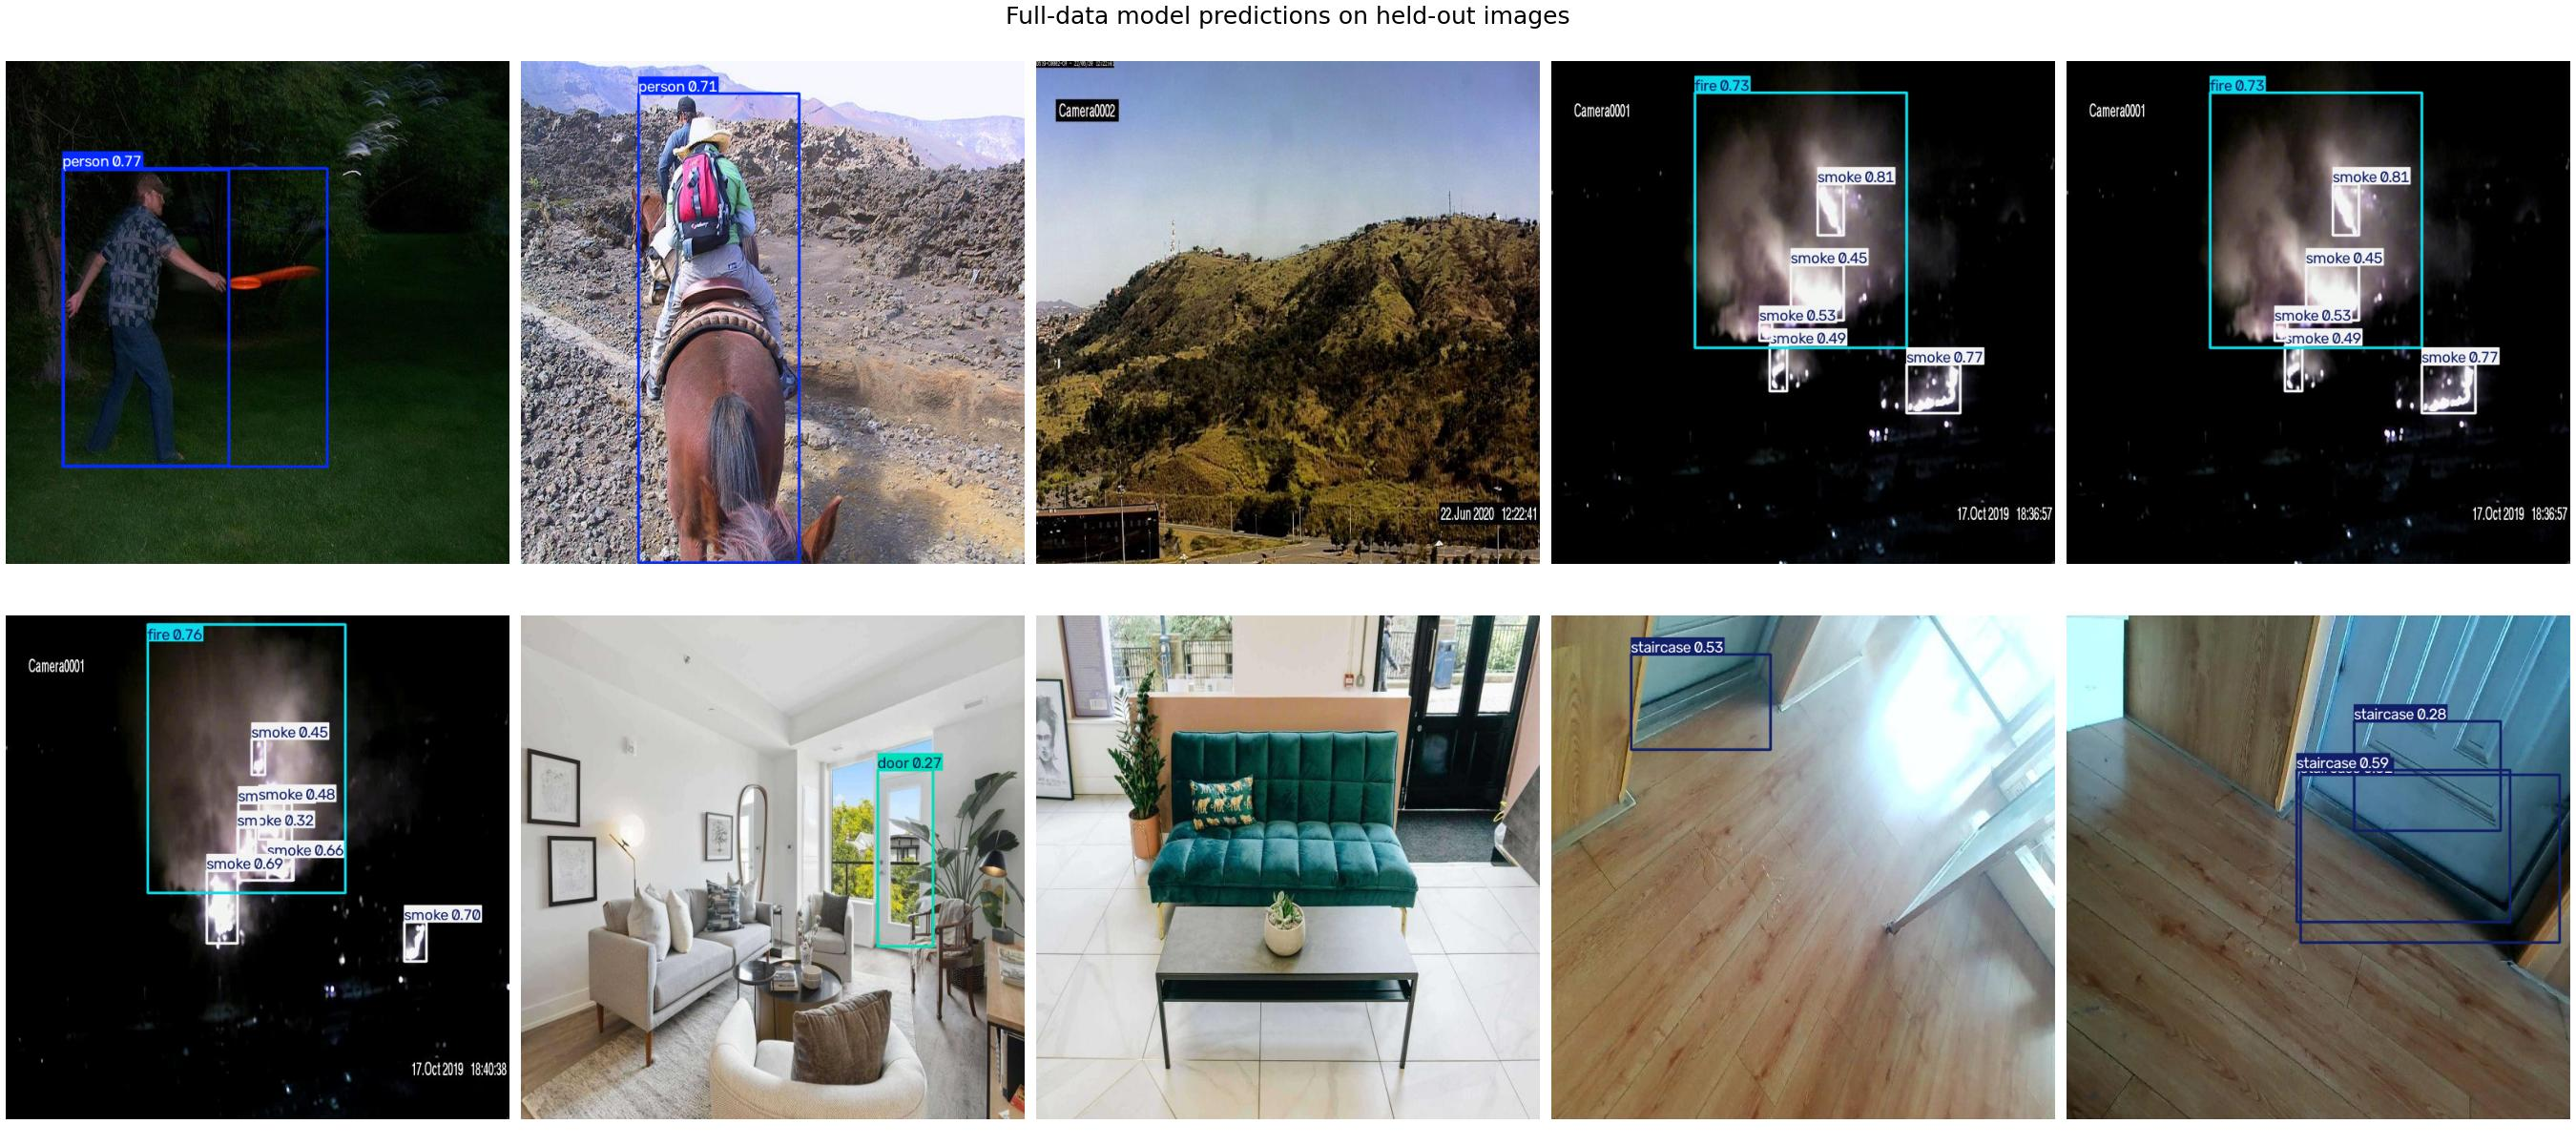

FINAL SAVED /content/drive/MyDrive/disaster_drone_backup/full_training/20260914_060759


In [ ]:
# RESUME FULL TRAINING — restore Drive backup, continue saved optimizer and epochs
from pathlib import Path
import shutil, zipfile, hashlib
archive=Path('/content/drive/MyDrive/disaster_drone_backup/datasets/indoor_elder_v3_yolov8.zip')
assert archive.is_file()
local_zip=Path('/content/indoor_elder_v3_yolov8.zip')
print('RESTORING DATASET FROM DRIVE',archive.stat().st_size,'bytes',flush=True)
shutil.copy2(archive,local_zip)
assert local_zip.stat().st_size==archive.stat().st_size
with zipfile.ZipFile(local_zip) as z:
    assert z.testzip() is None
    z.extractall('/content/disaster_source')
print('DATASET ZIP RESTORED AND CRC VERIFIED',flush=True)
# FULL DATA TRAINING — 30 epochs, persistent backups and final test
from pathlib import Path
import os,sys,json,shutil,hashlib,time,yaml
import torch
from ultralytics import YOLO
from IPython.display import display,HTML,Image,clear_output
assert torch.cuda.is_available(), 'GPU required'
assert Path('/content/drive/MyDrive').is_dir(), 'Mount Drive first'
source=Path('/content/disaster_source'); full=Path('/content/disaster_full_v2')
assert (source/'data.yaml').is_file(), 'Restore dataset ZIP first'
run_id='20260914_060759'
saved=Path('/content/drive/MyDrive/disaster_drone_backup/full_training')/run_id
assert (saved/'last.pt').is_file()
resume_archive=saved/('before_resume_'+time.strftime('%Y%m%d_%H%M%S'))
resume_archive.mkdir()
for p in list(saved.iterdir()):
    if p.is_file(): shutil.copy2(p,resume_archive/p.name)
original_audit=json.loads((saved/'audit.json').read_text())
local_run=Path('/content/full_training')/run_id
(local_run/'weights').mkdir(parents=True,exist_ok=True)
for fn in ['best.pt','last.pt']: shutil.copy2(saved/fn,local_run/'weights'/fn)
shutil.copy2(saved/'results.csv',local_run/'results.csv')
ckpt=torch.load(local_run/'weights/last.pt',map_location='cpu',weights_only=False)
resume_epoch=int(ckpt['epoch'])+1
assert 0 < resume_epoch < 30 and ckpt.get('optimizer') is not None
print('RESUMING AFTER EPOCH',resume_epoch,flush=True)
del ckpt
status_display=display(HTML('<h1>전체 데이터 학습 준비 중</h1><p>라벨 변환·중복 검사 후 최대 30회 학습합니다.</p>'),display_id=True)
def update_status(title,detail):
    import html
    status_display.update(HTML('<section style="padding:24px;background:#102138;color:white;border-radius:12px"><h1>'+html.escape(title)+'</h1><p>'+html.escape(detail)+'</p><p>Drive: '+html.escape(str(saved))+'</p></section>'))
def digest(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''): h.update(b)
    return h.hexdigest()
def backup_file(src,dst):
    src,dst=Path(src),Path(dst); tmp=dst.with_name(dst.name+'.partial')
    shutil.copy2(src,tmp)
    assert digest(src)==digest(tmp),'Backup checksum mismatch'
    tmp.replace(dst)
classes=['person','fire','smoke','door','staircase']
cfg=yaml.safe_load((source/'data.yaml').read_text());names=cfg['names'];names=dict(enumerate(names)) if isinstance(names,list) else names
remap={int(i):classes.index('staircase' if n=='stairs' else n) for i,n in names.items() if n in classes or n=='stairs'}
assert len(remap)==5
# Pixel-exact duplicates: prioritize test, then validation, then training.
from PIL import Image as PILImage
seen=set();audit={};duplicates=0
full=full/run_id
for split in ['test','valid','train']:
    image_out=full/split/'images';label_out=full/split/'labels'
    image_out.mkdir(parents=True);label_out.mkdir(parents=True)
    count=0;objects=[0]*5
    for image in sorted((source/split/'images').iterdir()):
        if image.suffix.lower() not in ['.jpg','.jpeg','.png','.bmp','.webp']: continue
        label=source/split/'labels'/(image.stem+'.txt')
        assert label.is_file(),str(label)
        with PILImage.open(image) as im:
            im=im.convert('RGB');key=hashlib.sha256(str(im.size).encode()+im.tobytes()).digest()
        if key in seen: duplicates+=1;continue
        seen.add(key);rows=[]
        for row in label.read_text().splitlines():
            fields=row.split()
            if not fields: continue
            assert len(fields)==5,str(label)
            old=int(fields[0]);vals=list(map(float,fields[1:]))
            assert all(0<=v<=1 for v in vals) and vals[2]>0 and vals[3]>0,str(label)
            if old in remap:
                new=remap[old];rows.append(str(new)+' '+' '.join(fields[1:]));objects[new]+=1
        try: os.link(image,image_out/image.name)
        except OSError: shutil.copy2(image,image_out/image.name)
        (label_out/label.name).write_text('\n'.join(rows)+'\n' if rows else '')
        count+=1
    audit[split]={'images':count,'objects':dict(zip(classes,objects))}
    print('DATA READY',split,audit[split],flush=True)
(full/'data.yaml').write_text(yaml.safe_dump({'path':str(full),'train':'train/images','val':'valid/images','test':'test/images','names':classes}))
(saved/'audit.json').write_text(json.dumps({'splits':audit,'pixel_duplicates_removed':duplicates,'source':'https://universe.roboflow.com/zeka-s-workspace/indoor-elder-objection/dataset/3'},indent=2))
backup_file(full/'data.yaml',saved/'data.yaml')
# Start fresh: earlier quick-model validation selection used a different split audit.
assert audit==original_audit['splits'], 'Restored data differs from original run'
model=YOLO(str(local_run/'weights/last.pt'))
started=time.time()
def checkpoint(t):
    for item in [t.last,t.best,t.csv]:
        if Path(item).is_file(): backup_file(item,saved/Path(item).name)
    epoch=t.epoch+1;remaining=(time.time()-started)/max(1,epoch-resume_epoch)*(30-epoch)/60
    (saved/'status.json').write_text(json.dumps({'epoch':epoch,'max_epochs':30,'estimated_remaining_minutes':remaining,'complete':False}))
    update_status('전체 데이터 학습 '+str(epoch)+'/30회 완료','모델 Drive 검증 저장 완료 · 남은 학습 예상 '+str(round(remaining))+'분 (평가 시간 별도)')
model.add_callback('on_model_save',checkpoint)
update_status('전체 데이터 GPU 학습 중',str(audit['train']['images'])+'장 · 최대 30회 · Tesla T4')
model.train(resume=True,device=0)
checkpoint(model.trainer)
update_status('전체 학습 완료 · 독립 테스트 평가 중','저장된 best.pt로 test 분할을 평가합니다.')
best=YOLO(str(saved/'best.pt'))
metrics=best.val(data=str(full/'data.yaml'),split='test',imgsz=640,batch=16,device=0,workers=2,plots=True,project='/content/full_evaluation',name=run_id)
report={'split':'test','GPU':torch.cuda.get_device_name(0),'metrics':{k:float(v) for k,v in metrics.results_dict.items()},'per_class':{},'speed_ms':metrics.speed,'audit':audit}
for i,c in enumerate(metrics.box.ap_class_index):
    p,r,ap50,ap=metrics.box.class_result(i)
    report['per_class'][best.names[int(c)]]={'precision':float(p),'recall':float(r),'AP50':float(ap50),'AP50_95':float(ap)}
(saved/'metrics.json').write_text(json.dumps(report,indent=2))
shutil.copytree(metrics.save_dir,saved/'test_evaluation',dirs_exist_ok=True)
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(13,5),layout='constrained')
cn=list(report['per_class']);v=[report['per_class'][n]['AP50'] for n in cn]
b=axs[0].barh(cn,v);axs[0].set_xlim(0,1);axs[0].bar_label(b,fmt='%.3f');axs[0].set_title('Full training: TEST AP50')
import pandas as pd
hist=pd.read_csv(saved/'results.csv');hist.columns=hist.columns.str.strip();axs[1].plot(hist['epoch'],hist['metrics/mAP50(B)'],label='Validation mAP50');axs[1].legend();axs[1].set_xlabel('Epoch')
fig.savefig(saved/'summary_chart.png',dpi=160);plt.close(fig)
testimgs=sorted((full/'test/images').iterdir());chosen=[]
for c in range(5):
    candidates=[p for p in testimgs if any(int(r.split()[0])==c for r in (full/'test/labels'/(p.stem+'.txt')).read_text().splitlines() if r.strip())]
    chosen.extend(candidates[:2])
fig,axs=plt.subplots(2,5,figsize=(18,8),layout='constrained')
for ax,p in zip(axs.flat,chosen):
    pred=best.predict(str(p),device=0,conf=.25,verbose=False)[0];ax.imshow(pred.plot()[...,::-1]);ax.axis('off')
fig.suptitle('Full-data model predictions on held-out images');fig.savefig(saved/'predictions.jpg',dpi=150);plt.close(fig)
weak=sorted(report['per_class'],key=lambda n:report['per_class'][n]['AP50'])
notes='보완 우선 클래스: '+', '.join(weak[:2])+' · 계단 데이터 추가 수집 · 유사 장면 누수 점검 · 실제 D435i/Jetson 검증 · 탐지와 깊이 지도의 통합 실측 필요'
(saved/'improvements.txt').write_text(notes,encoding='utf-8')
(saved/'status.json').write_text(json.dumps({'complete':True,'epochs':len(hist)}))
update_status('전체 데이터 학습·테스트 완료','Test mAP50 '+format(metrics.box.map50,'.3f')+' · '+notes)
display(Image(filename=str(saved/'summary_chart.png')));display(Image(filename=str(saved/'predictions.jpg')))
print('FINAL SAVED',saved,flush=True)



In [ ]:
from google.colab import drive
from pathlib import Path
import subprocess
print(subprocess.run(['nvidia-smi','--query-gpu=name,memory.total','--format=csv,noheader'],capture_output=True,text=True).stdout)
drive.mount('/content/drive')
for base in [Path('/content'),Path('/content/drive/MyDrive')]:
    print('SCAN',base)
    print([p.name for p in ba비se.iterdir() if any(s in p.name.lower() for s in ['disaster','drone','공경진','indoor','best.pt'])])


Tesla T4, 15360 MiB

Mounted at /content/drive
SCAN /content
[]
SCAN /content/drive/MyDrive
[]


DRIVE MODEL VERIFIED: 6247082 bytes
Actual new 10-epoch model predictions; not previous 0.636 model; no depth data.


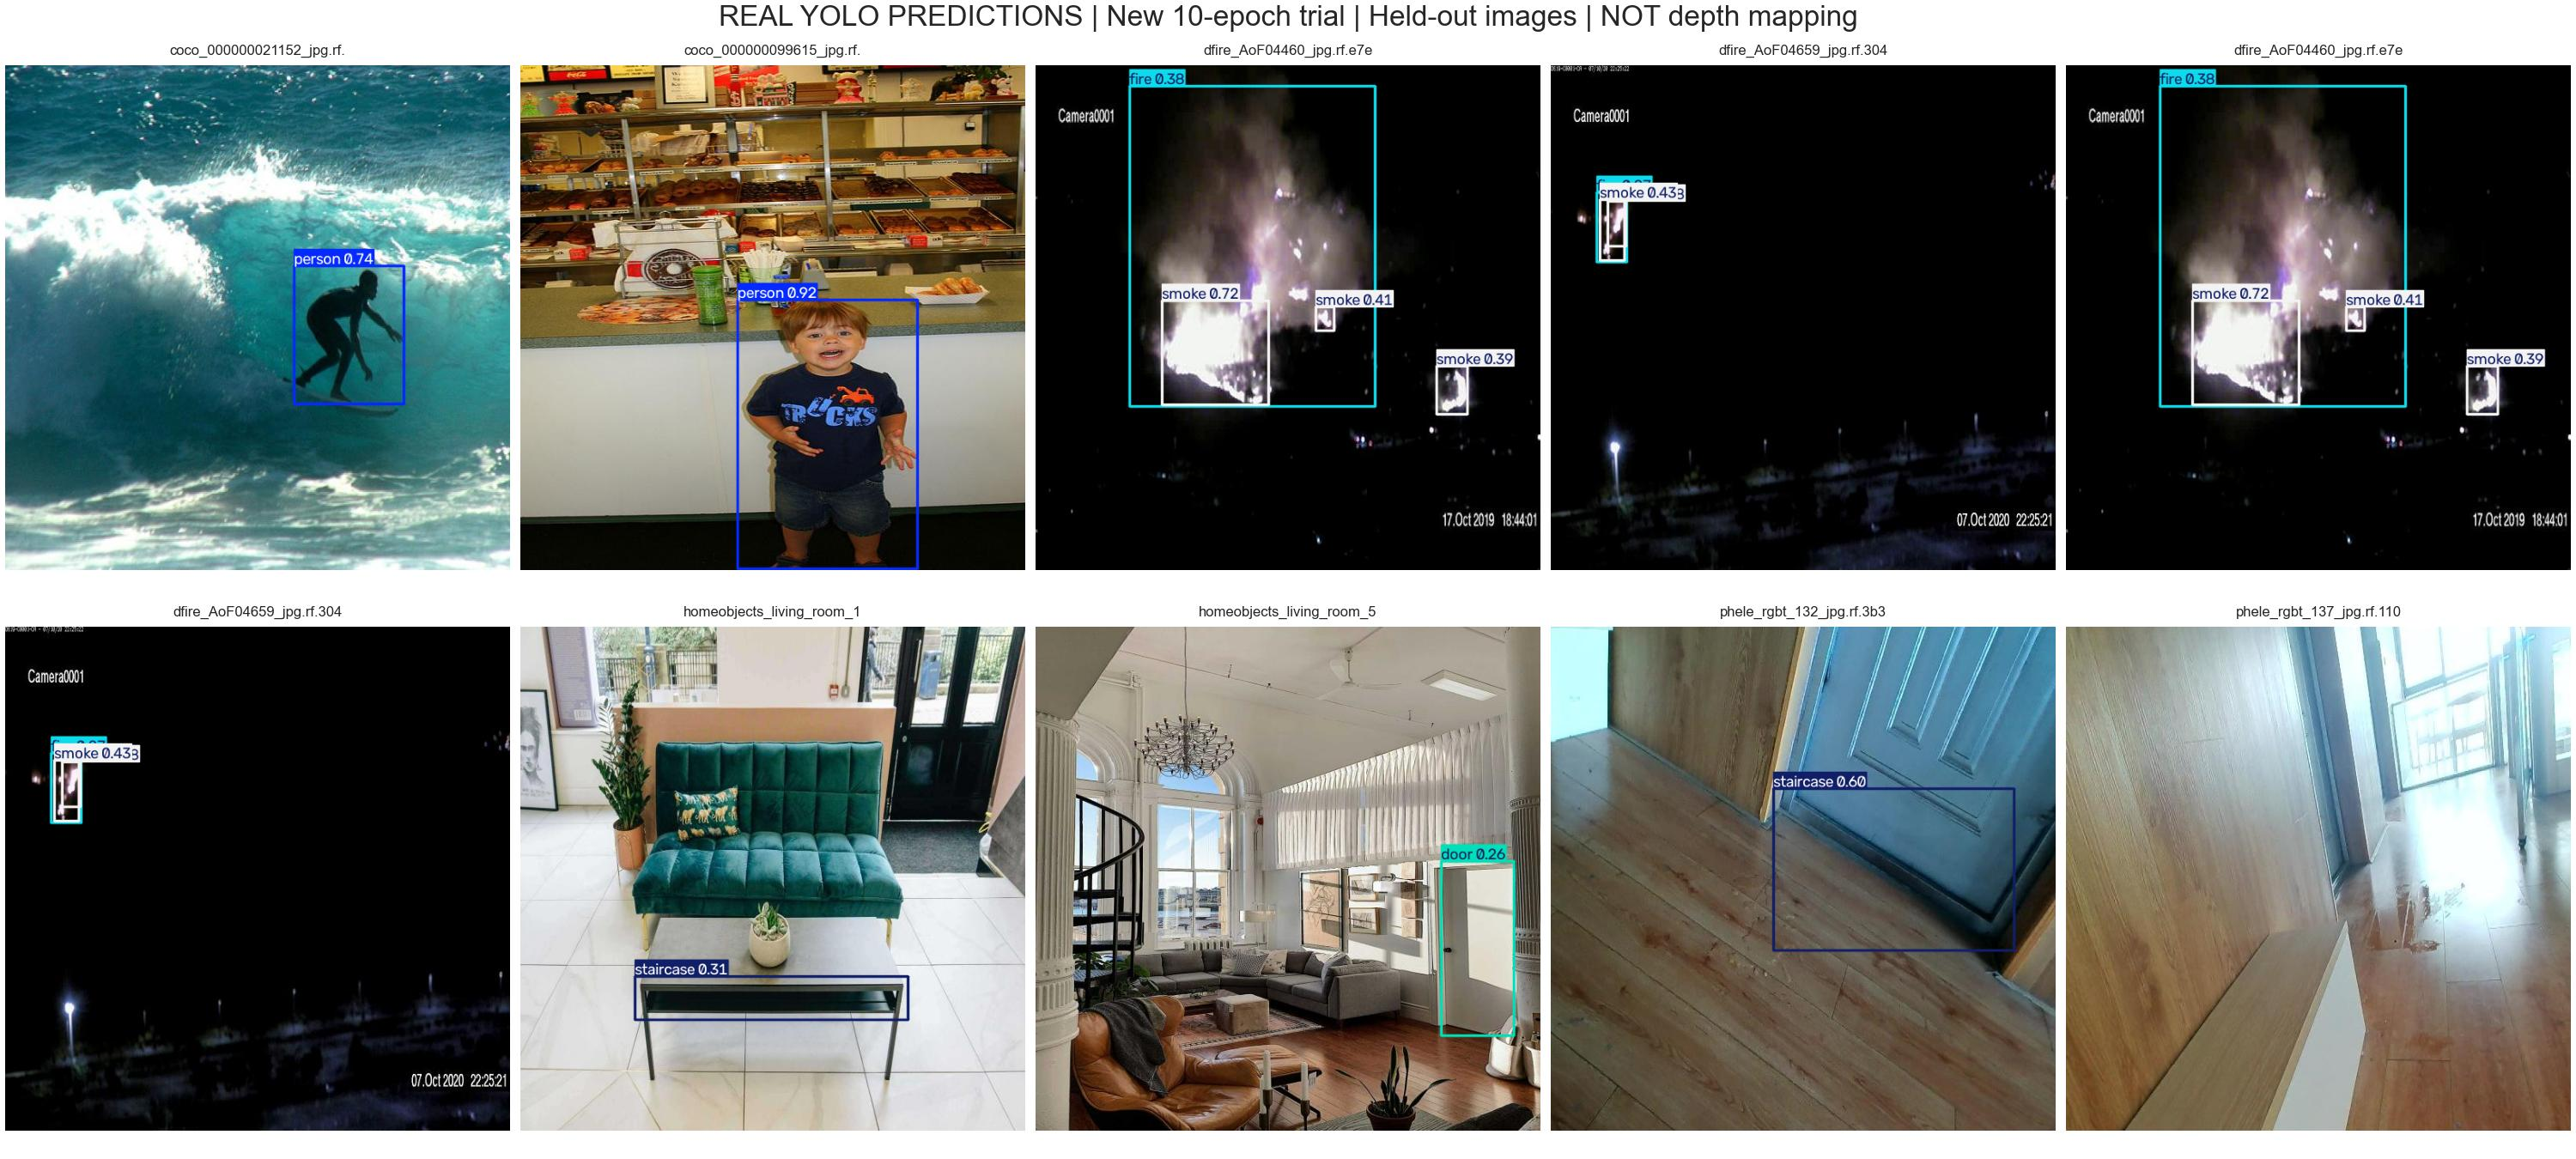

SAVED: /content/drive/MyDrive/disaster_drone_backup/visual_trial


In [ ]:
from pathlib import Path
import hashlib,json
from IPython.display import display,Image
p=Path('/content/drive/MyDrive/disaster_drone_backup/visual_trial')
local=Path('/content/visual_training/trial/weights/best.pt')
assert hashlib.sha256(local.read_bytes()).hexdigest()==hashlib.sha256((p/'best.pt').read_bytes()).hexdigest()
print('DRIVE MODEL VERIFIED:',(p/'best.pt').stat().st_size,'bytes')
print('Actual new 10-epoch model predictions; not previous 0.636 model; no depth data.')
display(Image(filename=str(p/'actual_predictions.jpg'),width=1500))
print('SAVED:',p)


In [ ]:
from pathlib import Path
import os,json
for base in [Path('/content'),Path('/content/drive/MyDrive')]:
    for root,dirs,files in os.walk(base):
        dirs[:]=[d for d in dirs if d not in ['.git','node_modules','sample_data']]
        for name in files:
            if name in ['best.pt','last.pt','metrics.json','results.csv']:
                p=Path(root)/name
                print(str(p),p.stat().st_size)
                if name=='metrics.json': print(p.read_text()[:1800])

/content/drive/MyDrive/Capstone_AI_Project_2026/02_데이터/02_raw_외부데이터/데이터 수집_조선기/Colab_사전점검_실행결과_조선기/20260913_183252_0d3e14/best.pt 44789259
/content/drive/MyDrive/Capstone_AI_Project_2026/02_데이터/02_raw_외부데이터/데이터 수집_조선기/Colab_사전점검_실행결과_조선기/20260913_183252_0d3e14/metrics.json 176
{
  "accuracy": 0.95,
  "precision": 0.5,
  "recall": 0.2,
  "f1": 0.2857142857142857,
  "confusion_matrix": [
    [
      94,
      1
    ],
    [
      4,
      1
    ]
  ]
}
/content/drive/MyDrive/Capstone_베이스라인_실행결과/20260913_183252_0d3e14/best.pt 44789259
/content/drive/MyDrive/Capstone_베이스라인_실행결과/20260913_183252_0d3e14/metrics.json 176
{
  "accuracy": 0.95,
  "precision": 0.5,
  "recall": 0.2,
  "f1": 0.2857142857142857,
  "confusion_matrix": [
    [
      94,
      1
    ],
    [
      4,
      1
    ]
  ]
}
/content/drive/MyDrive/Capstone_AI_Project_2026/02_데이터/02_raw_외부데이터/데이터 수집_조선기/Colab_ᄉ

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 8.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
test 60
valid 233
train 1143
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/disaster_visual_tri

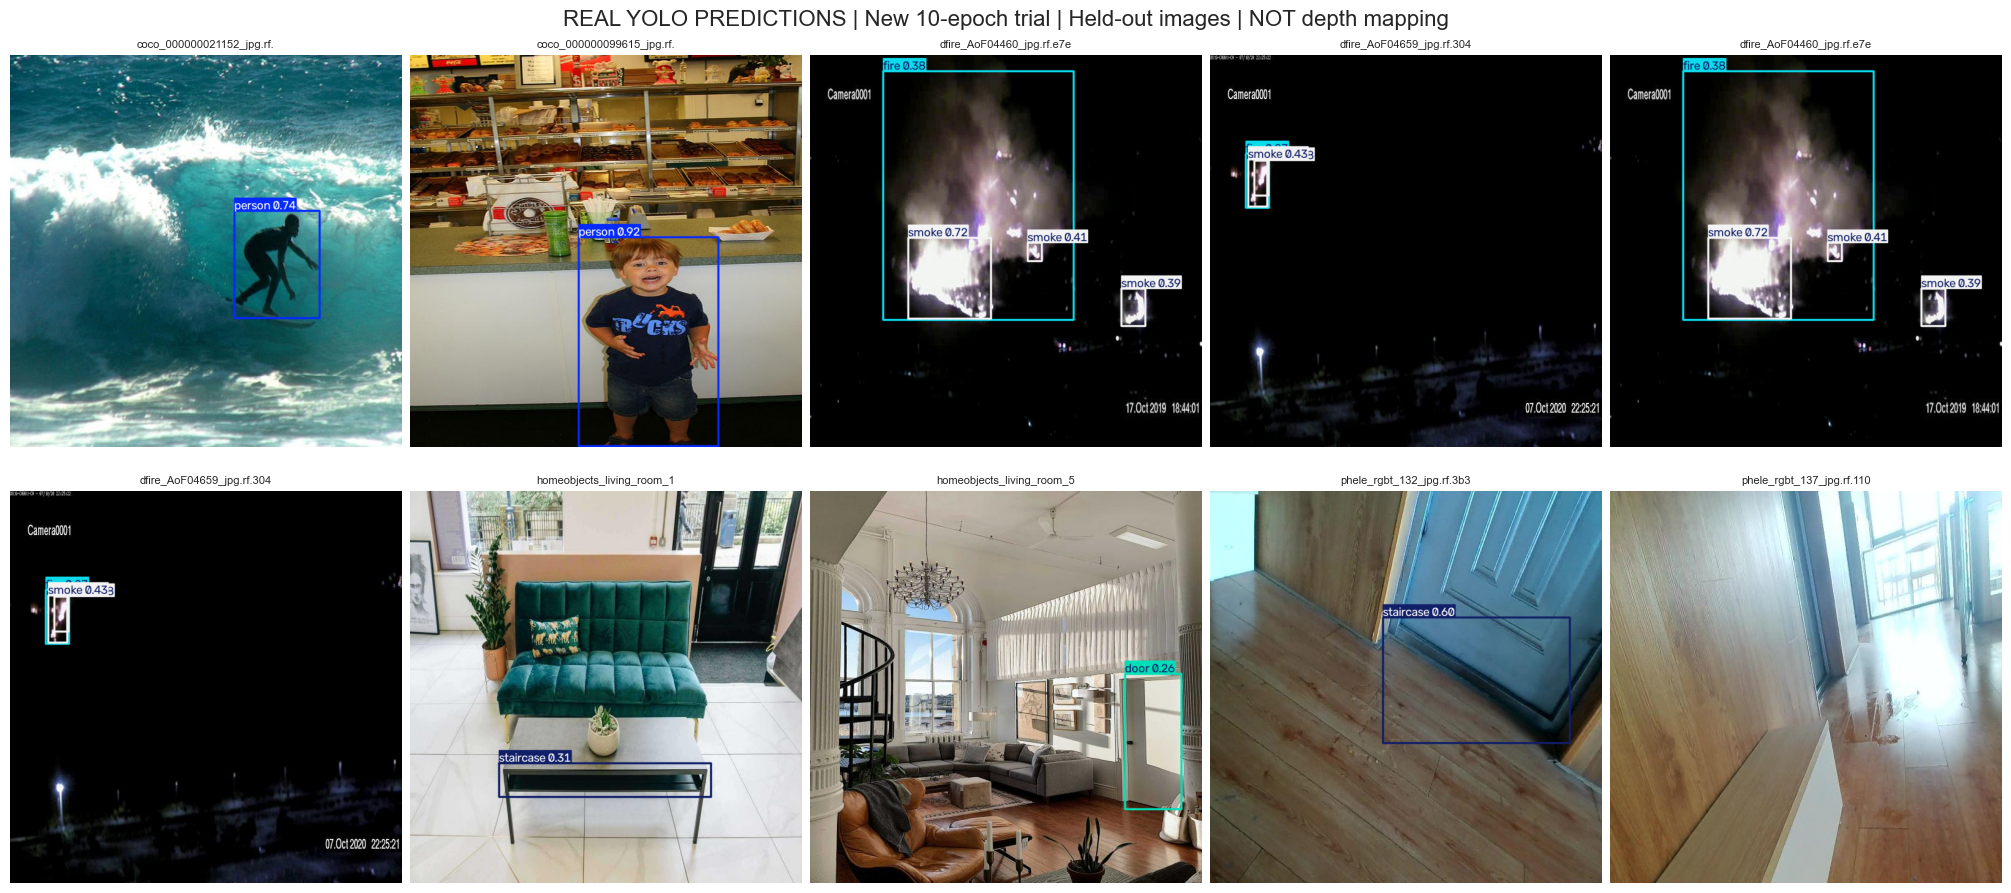

REAL PREDICTIONS SAVED: /content/drive/MyDrive/disaster_drone_backup/visual_trial


In [ ]:
%pip -q install ultralytics pyyaml
from pathlib import Path
import yaml,random,shutil,json,hashlib
from ultralytics import YOLO
import torch
assert torch.cuda.is_available()
src=Path('/content/disaster_source');dst=Path('/content/disaster_visual_trial')
backup=Path('/content/drive/MyDrive/disaster_drone_backup/visual_trial');backup.mkdir(parents=True,exist_ok=True)
classes=['person','fire','smoke','door','staircase']
cfg=yaml.safe_load((src/'data.yaml').read_text());sn=cfg['names'];sn=dict(enumerate(sn)) if isinstance(sn,list) else sn
remap={int(i):classes.index('staircase' if n=='stairs' else n) for i,n in sn.items() if n in classes or n=='stairs'}
rng=random.Random(42);seen=set()
for split,limit in [('test',12),('valid',50),('train',250)]:
    groups={i:[] for i in range(5)}
    for p in sorted((src/split/'labels').glob('*.txt')):
        ids={int(r.split()[0]) for r in p.read_text().splitlines() if r.strip()}
        for old,new in remap.items():
            if old in ids: groups[new].append(p)
    selected=set()
    for group in groups.values(): selected.update(rng.sample(group,min(limit,len(group))))
    (dst/split/'images').mkdir(parents=True,exist_ok=True);(dst/split/'labels').mkdir(parents=True,exist_ok=True)
    for p in sorted(selected):
        imgs=list((src/split/'images').glob(p.stem+'.*'))
        if not imgs: continue
        image=imgs[0];digest=hashlib.sha256(image.read_bytes()).hexdigest()
        if digest in seen: continue
        seen.add(digest)
        rows=[]
        for row in p.read_text().splitlines():
            parts=row.split()
            if parts and int(parts[0]) in remap: rows.append(str(remap[int(parts[0])])+' '+' '.join(parts[1:]))
        shutil.copy2(image,dst/split/'images'/image.name);(dst/split/'labels'/p.name).write_text('\n'.join(rows)+'\n')
    print(split,len(list((dst/split/'images').iterdir())),flush=True)
(dst/'data.yaml').write_text(yaml.safe_dump({'path':str(dst),'train':'train/images','val':'valid/images','test':'test/images','names':classes}))
model=YOLO('yolov8n.pt')
def save_checkpoint(t):
    for p in [t.last,t.best,t.csv]:
        if Path(p).is_file(): shutil.copy2(p,backup/Path(p).name)
model.add_callback('on_model_save',save_checkpoint)
model.train(data=str(dst/'data.yaml'),epochs=10,imgsz=640,batch=16,device=0,workers=2,seed=42,close_mosaic=0,project='/content/visual_training',name='trial',exist_ok=True,plots=True)
save_checkpoint(model.trainer)
import matplotlib.pyplot as plt
detector=YOLO(str(backup/'best.pt'))
testimages=sorted((dst/'test/images').iterdir());selected=[]
for c in range(5):
    candidates=[p for p in testimages if any(int(r.split()[0])==c for r in (dst/'test/labels'/(p.stem+'.txt')).read_text().splitlines() if r.strip())]
    selected.extend(candidates[:2])
fig,axes=plt.subplots(2,5,figsize=(20,9),layout='constrained')
records=[]
for ax,p in zip(axes.flat,selected):
    r=detector.predict(str(p),conf=.25,device=0,verbose=False)[0]
    ax.imshow(r.plot()[...,::-1]);ax.axis('off');ax.set_title(p.stem[:25],fontsize=8)
    r.save(filename=str(backup/('pred_'+p.name)))
    records.append({'image':p.name,'predictions':json.loads(r.to_json())})
for ax in list(axes.flat)[len(selected):]: ax.axis('off')
fig.suptitle('REAL YOLO PREDICTIONS | New 10-epoch trial | Held-out images | NOT depth mapping',fontsize=16)
fig.savefig(backup/'actual_predictions.jpg',dpi=150);plt.show()
(backup/'predictions.json').write_text(json.dumps(records,indent=2))
print('REAL PREDICTIONS SAVED:',backup,flush=True)


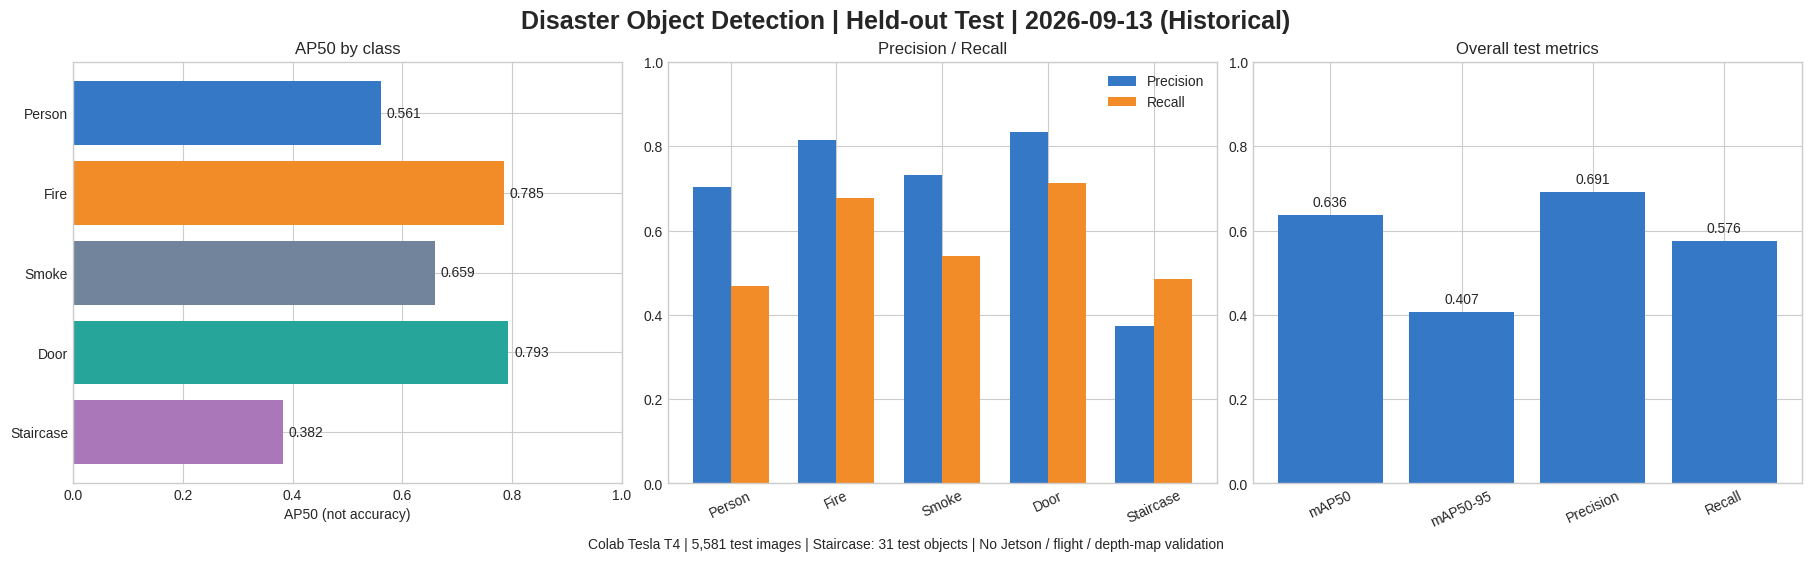

Charts saved: /content/drive/MyDrive/disaster_drone_backup/reports/20260913_historical


In [ ]:
# Historical test results from this notebook, evaluated 2026-09-13. NOT a new training run.
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import json
names=['Person','Fire','Smoke','Door','Staircase']
ap50=[.5608430023,.7849813249,.6593933555,.7934284483,.3823845752]
precision=[.7025476202,.8139678556,.7322902231,.8335365442,.3730623039]
recall=[.4678872421,.6770361991,.5398663697,.7125082235,.4838709677]
summary={'mAP50':.6362061412,'mAP50-95':.4071245625,'Precision':.6910809094,'Recall':.5762338004}
plt.style.use('seaborn-v0_8-whitegrid')
fig,axs=plt.subplots(1,3,figsize=(18,5.5),layout='constrained')
fig.suptitle('Disaster Object Detection | Held-out Test | 2026-09-13 (Historical)',fontsize=18,fontweight='bold')
colors=['#3478c6','#f28c28','#72849c','#26a69a','#aa78b9']
b=axs[0].barh(names,ap50,color=colors);axs[0].invert_yaxis();axs[0].set_xlim(0,1);axs[0].bar_label(b,fmt='%.3f',padding=4);axs[0].set_title('AP50 by class');axs[0].set_xlabel('AP50 (not accuracy)')
x=np.arange(5);axs[1].bar(x-.18,precision,.36,label='Precision',color='#3478c6');axs[1].bar(x+.18,recall,.36,label='Recall',color='#f28c28');axs[1].set_xticks(x,names,rotation=25);axs[1].set_ylim(0,1);axs[1].legend();axs[1].set_title('Precision / Recall')
b=axs[2].bar(list(summary),list(summary.values()),color='#3478c6');axs[2].bar_label(b,fmt='%.3f',padding=4);axs[2].set_ylim(0,1);axs[2].tick_params(axis='x',rotation=25);axs[2].set_title('Overall test metrics')
fig.supxlabel('Colab Tesla T4 | 5,581 test images | Staircase: 31 test objects | No Jetson / flight / depth-map validation',fontsize=10)
out=Path('/content/drive/MyDrive/disaster_drone_backup/reports/20260913_historical');out.mkdir(parents=True,exist_ok=True)
fig.savefig(out/'test_metrics.png',dpi=200,bbox_inches='tight');fig.savefig(out/'test_metrics.pdf',bbox_inches='tight')
(out/'metrics_used.json').write_text(json.dumps({'evaluated':'2026-09-13','historical':True,'names':names,'AP50':ap50,'precision':precision,'recall':recall,'overall':summary},indent=2))
plt.show()
print('Charts saved:',out)


In [ ]:
from pathlib import Path
import os
base = Path('/content/drive/MyDrive')
found = []
for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in ['.git', '.ipynb_checkpoints']]
    for name in files:
        if name == 'best.pt' or (name.endswith('.zip') and any(s in name.lower() for s in ['disaster','indoor','drone'])):
            found.append(str(Path(root)/name))
print('EXISTING BACKUPS:', found)


EXISTING BACKUPS: ['/content/drive/MyDrive/Capstone_AI_Project_2026/02_데이터/02_raw_외부데이터/데이터 수집_조선기/Colab_사전점검_실행결과_조선기/20260913_183252_0d3e14/best.pt', '/content/drive/MyDrive/Capstone_베이스라인_실행결과/20260913_183252_0d3e14/best.pt']


In [ ]:
%pip -q install roboflow
from getpass import getpass
from roboflow import Roboflow
from pathlib import Path
import shutil, zipfile, hashlib, json
backup = Path('/content/drive/MyDrive/disaster_drone_backup/datasets')
backup.mkdir(parents=True, exist_ok=True)
rf = Roboflow(api_key=getpass('Roboflow API key (not saved): '))
dataset = rf.workspace('zeka-s-workspace').project('indoor-elder-objection').version(3).download('yolov8', location='/content/disaster_source')
archive = Path(shutil.make_archive('/content/indoor_elder_v3_yolov8', 'zip', dataset.location))
def sha256(p):
    h = hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''): h.update(chunk)
    return h.hexdigest()
target = backup / archive.name
shutil.copy2(archive, target.with_suffix('.zip.partial'))
assert sha256(archive) == sha256(target.with_suffix('.zip.partial'))
target.with_suffix('.zip.partial').replace(target)
with zipfile.ZipFile(target) as z: assert z.testzip() is None
print('DRIVE BACKUP VERIFIED:', target, 'bytes:', target.stat().st_size)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 136.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.0 MB/s eta 0:00:00
Roboflow API key (not saved): ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/disaster_source in yolov8:: 100%|██████████| 74425/74425 [00:13<00:00, 5628.40it/s] 


DRIVE BACKUP VERIFIED: /content/drive/MyDrive/disaster_drone_backup/datasets/indoor_elder_v3_yolov8.zip bytes: 1774425375


In [ ]:
%pip -q install "ultralytics>=8.3,<9" pyyaml
import torch, ultralytics
print("torch:",torch.__version__,"ultralytics:",ultralytics.__version__)
print("GPU:",torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (demo supported)")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 9.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
torch: 2.11.0+cu128 ultralytics: 8.4.150
GPU: Tesla T4


In [ ]:
from pathlib import Path
import json, sys, subprocess
ROOT=Path("/content/disaster_drone")
ROOT.mkdir(exist_ok=True)
FILES={'app.py': '"""F450 project perception prototype: RealSense, YOLO, local depth map."""\nimport argparse\nfrom datetime import datetime\nimport json\nfrom pathlib import Path\nimport time\nimport cv2\nimport numpy as np\nfrom mapping import project, obstacle_grid, box_distance\n\nCLASSES = {\'person\', \'fire\', \'smoke\', \'door\', \'staircase\'}\n\n\ndef frames(args):\n    if args.source == \'demo\':\n        for i in range(args.frames or 120):\n            color = np.full((480,640,3), 35, np.uint8)\n            depth = np.full((480,640), 4.0, np.float32)\n            depth[160:320, 240:400] = 2.0 + .2*np.sin(i/20)\n            color[160:320,240:400] = (20,120,220)\n            yield color, depth, (600.,600.,319.5,239.5)\n        return\n    import pyrealsense2 as rs\n    pipeline, config = rs.pipeline(), rs.config()\n    if args.source == \'bag\':\n        config.enable_device_from_file(str(args.bag), repeat_playback=False)\n    else:\n        config.enable_stream(rs.stream.depth,640,480,rs.format.z16,30)\n        config.enable_stream(rs.stream.color,640,480,rs.format.bgr8,30)\n    profile = pipeline.start(config)\n    try:\n        if args.source == \'bag\':\n            profile.get_device().as_playback().set_real_time(False)\n        scale = profile.get_device().first_depth_sensor().get_depth_scale()\n        align = rs.align(rs.stream.color)\n        count = 0\n        while not args.frames or count < args.frames:\n            try:\n                aligned = align.process(pipeline.wait_for_frames(5000))\n            except RuntimeError:\n                if args.source == \'bag\' and profile.get_device().as_playback().current_status() == rs.playback_status.stopped:\n                    break\n                raise\n            df,cf = aligned.get_depth_frame(),aligned.get_color_frame()\n            if not df or not cf:\n                continue\n            k = df.profile.as_video_stream_profile().intrinsics\n            color = np.asanyarray(cf.get_data())\n            if cf.profile.format() == rs.format.rgb8:\n                color = cv2.cvtColor(color,cv2.COLOR_RGB2BGR)\n            elif cf.profile.format() != rs.format.bgr8:\n                raise ValueError(\'Recording must contain RGB8 or BGR8 color\')\n            yield color, np.asanyarray(df.get_data()).astype(np.float32)*scale, (k.fx,k.fy,k.ppx,k.ppy)\n            count += 1\n    finally:\n        pipeline.stop()\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--source\', choices=[\'demo\',\'realsense\',\'bag\'], default=\'demo\')\n    p.add_argument(\'--bag\',type=Path)\n    p.add_argument(\'--weights\',type=Path)\n    p.add_argument(\'--device\',default=\'cpu\',help=\'cpu or CUDA device index, e.g. 0\')\n    p.add_argument(\'--conf\',type=float,default=.35)\n    p.add_argument(\'--frames\',type=int,default=0,help=\'0: until stopped (demo:120)\')\n    p.add_argument(\'--headless\',action=\'store_true\')\n    p.add_argument(\'--out\',type=Path,default=Path(\'runs\'))\n    args = p.parse_args()\n    if args.frames < 0 or not 0 < args.conf < 1:\n        p.error(\'frames must be nonnegative and confidence between 0 and 1\')\n    if args.source == \'bag\' and (not args.bag or not args.bag.is_file()):\n        p.error(\'--bag must point to an existing RealSense recording\')\n    model = None\n    if args.weights:\n        if not args.weights.is_file():\n            p.error(\'Model file not found; provide your trained best.pt\')\n        if args.source == \'demo\':\n            p.error(\'Synthetic demo is for mapping only; use real data for inference\')\n        from ultralytics import YOLO\n        model = YOLO(str(args.weights))\n        names = model.names.values() if isinstance(model.names,dict) else model.names\n        if set(names) != CLASSES:\n            p.error(\'Model must contain exactly person/fire/smoke/door/staircase; got \'+str(list(names)))\n    output = args.out / datetime.now().strftime(\'%Y%m%d_%H%M%S_%f\')\n    output.mkdir(parents=True)\n    timings, count = [], 0\n    stream = frames(args)\n    try:\n        with (output/\'detections.jsonl\').open(\'w\',encoding=\'utf-8\') as log:\n            for color, depth, k in stream:\n                started = time.perf_counter()\n                detections = []\n                annotated = color.copy()\n                inference_ms = None\n                if model is not None:\n                    t = time.perf_counter()\n                    result = model.predict(color,device=args.device,conf=args.conf,imgsz=640,verbose=False)[0]\n                    boxes = result.boxes.data.cpu().numpy()  # synchronize before timing\n                    inference_ms = (time.perf_counter()-t)*1000\n                    for x1,y1,x2,y2,confidence,cls in boxes:\n                        distance = box_distance(depth,(x1,y1,x2,y2))\n                        label = result.names[int(cls)]\n                        detections.append(dict(label=label,confidence=float(confidence),\n                            box=[float(x1),float(y1),float(x2),float(y2)],depth_m=distance))\n                        cv2.rectangle(annotated,(int(x1),int(y1)),(int(x2),int(y2)),(0,150,255),2)\n                        text = f\'{label} {confidence:.2f}\' + (f\' {distance:.2f}m\' if distance else \'\')\n                        cv2.putText(annotated,text,(max(0,int(x1)),max(20,int(y1)-5)),0,.5,(0,150,255),1)\n                grid = obstacle_grid(project(depth,k))\n                map_image = np.full((*grid.shape,3),55,np.uint8)\n                map_image[grid > 0] = (0,150,255)\n                map_image = cv2.resize(map_image,(640,480),interpolation=cv2.INTER_NEAREST)\n                cv2.putText(map_image,\'CAMERA LOCAL: 8m wide / 6m forward\',(10,25),0,.55,(255,255,255),1)\n                cv2.putText(map_image,\'GRAY = UNKNOWN | NOT SLAM\',(10,455),0,.6,(255,255,255),1)\n                status = \'SYNTHETIC DEMO - NO AI\' if args.source == \'demo\' else (\'LIVE AI\' if model else \'DEPTH ONLY - NO MODEL\')\n                cv2.putText(annotated,status,(10,25),0,.65,(0,255,255),2)\n                dashboard = np.hstack((annotated,map_image))\n                elapsed = (time.perf_counter()-started)*1000\n                timings.append(elapsed)\n                log.write(json.dumps(dict(frame=count,unix_time=time.time(),source=args.source,\n                    inference_pipeline_ms=inference_ms,processing_ms=elapsed,detections=detections),allow_nan=False)+\'\\n\')\n                if count % 30 == 0:\n                    if not cv2.imwrite(str(output/\'dashboard.png\'),dashboard):\n                        raise IOError(\'Failed to save dashboard\')\n                    np.savez_compressed(output/\'latest_depth.npz\',depth_m=depth,intrinsics=np.array(k),obstacles=grid)\n                count += 1\n                if not args.headless:\n                    cv2.imshow(\'Disaster drone perception\',dashboard)\n                    if cv2.waitKey(1)&0xff == ord(\'q\'):\n                        break\n    except KeyboardInterrupt:\n        pass\n    finally:\n        stream.close()\n        if not args.headless:\n            cv2.destroyAllWindows()\n        (output/\'summary.json\').write_text(json.dumps(dict(frames=count,source=args.source,\n            model=str(args.weights) if args.weights else None,\n            median_processing_ms=float(np.median(timings)) if timings else None,\n            note=\'Host processing time excludes acquisition, output, and display; not mAP or flight validation\'),indent=2),encoding=\'utf-8\')\n    print(f\'Saved {count} frames: {output}\')\n\n\nif __name__ == \'__main__\':\n    main()\n', 'data.example.yaml': '# Change path; class IDs MUST match the labels in your existing dataset.\npath: /home/USER/datasets/disaster\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: person\n  1: fire\n  2: smoke\n  3: door\n  4: staircase\n', 'doctor.py': '"""Read-only environment check. Does not connect to or arm a flight controller."""\nimport importlib\nimport json\nimport platform\nfrom pathlib import Path\nimport sys\n\ndef main():\n    report={\'architecture\':platform.machine(),\'python\':sys.version,\'executable\':sys.executable,\n            \'venv\':sys.prefix!=sys.base_prefix,\'expected_hardware\':\'Orin Nano Super / D435i / Pixhawk 6C / F450\'}\n    release=Path(\'/etc/nv_tegra_release\')\n    report[\'l4t\']=release.read_text().strip() if release.exists() else \'Not on Jetson\'\n    for name in [\'numpy\',\'cv2\',\'torch\',\'torchvision\',\'ultralytics\',\'tensorrt\',\'pyrealsense2\',\'pymavlink\']:\n        try:\n            module=importlib.import_module(name)\n            report[name]={\'version\':str(getattr(module,\'__version__\',\'import OK\'))}\n            if name==\'torch\':\n                report[name][\'cuda_available\']=module.cuda.is_available()\n                report[name][\'cuda_version\']=module.version.cuda\n                if module.cuda.is_available():\n                    report[name][\'gpu\']=module.cuda.get_device_name(0)\n            if name==\'pyrealsense2\':\n                report[name][\'devices\']=[d.get_info(module.camera_info.name) for d in module.context().query_devices()]\n        except Exception as exc:\n            report[name]={\'error\':str(exc)}\n    print(json.dumps(report,ensure_ascii=False,indent=2))\n\nif __name__==\'__main__\': main()\n', 'export_engine.py': '"""Export trusted YOLOv8 weights on the target Jetson, using its TensorRT stack."""\nimport argparse\nfrom pathlib import Path\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--weights\',type=Path,required=True)\n    args=parser.parse_args()\n    if not args.weights.is_file() or args.weights.suffix!=\'.pt\':\n        parser.error(\'Provide an existing trusted .pt model\')\n    import torch\n    if not torch.cuda.is_available():\n        parser.error(\'CUDA unavailable; fix target Jetson environment first\')\n    from ultralytics import YOLO\n    model=YOLO(str(args.weights))\n    result=model.export(format=\'engine\',imgsz=640,half=True,device=0,batch=1)\n    print(result)\n\nif __name__==\'__main__\': main()\n', 'mapping.py': '"""Camera-local obstacle projection. Not SLAM or a traversability map."""\nimport numpy as np\n\n\ndef project(depth, intrinsics, stride=4, max_depth=6.0):\n    fx, fy, cx, cy = intrinsics\n    if fx <= 0 or fy <= 0 or stride < 1:\n        raise ValueError(\'Invalid intrinsics or stride\')\n    v, u = np.mgrid[0:depth.shape[0]:stride, 0:depth.shape[1]:stride]\n    z = depth[::stride, ::stride]\n    valid = np.isfinite(z) & (z >= 0.2) & (z <= max_depth)\n    return np.column_stack(((u[valid]-cx)*z[valid]/fx,\n                            (v[valid]-cy)*z[valid]/fy, z[valid]))\n\n\ndef obstacle_grid(points, width=8.0, forward=6.0, resolution=0.05):\n    # x right, y down, z forward in camera frame; thin horizontal slab.\n    grid = np.zeros((int(round(forward/resolution))+1,\n                     int(round(width/resolution))+1), dtype=np.uint8)\n    p = points[np.isfinite(points).all(axis=1) & (np.abs(points[:, 1]) <= 0.35)]\n    col = np.floor((p[:, 0]+width/2)/resolution).astype(int)\n    row = grid.shape[0]-1-np.floor(p[:, 2]/resolution).astype(int)\n    ok = (col >= 0) & (col < grid.shape[1]) & (row >= 0) & (row < grid.shape[0])\n    grid[row[ok], col[ok]] = 255\n    return grid  # Zero means unknown, never confirmed free space.\n\n\ndef box_distance(depth, xyxy):\n    x1,y1,x2,y2 = xyxy\n    h,w = depth.shape\n    # Central half reduces background contamination; still a depth estimate.\n    xa,xb = max(0,int(x1+(x2-x1)*.25)), min(w,int(x2-(x2-x1)*.25))\n    ya,yb = max(0,int(y1+(y2-y1)*.25)), min(h,int(y2-(y2-y1)*.25))\n    roi = depth[ya:yb,xa:xb]\n    values = roi[np.isfinite(roi) & (roi >= .2) & (roi <= 6)]\n    return float(np.median(values)) if values.size >= 5 else None\n', 'README.md': '# 공경진 재난 정찰 드론 — 인식 프로토타입\n\n발표 자료를 참고해 새로 작성한 코드입니다. 기존 Jetson 코드·학습 가중치는 포함하지 않습니다.\n\n최신 사용자 제공 장비 기준: NVIDIA Jetson Orin Nano Super Developer Kit (ARM64), Intel RealSense D435i, Pixhawk 6C 계열, F450. JetPack/Python/CUDA의 정확한 버전은 아직 미확인입니다. 과거 이미지의 Orin NX·D435 표기는 이 프로젝트의 장비 표기로 사용하지 않습니다.\n\n## 구현 범위\n\n- RealSense D435i RGB/깊이 정렬 및 미터 단위 깊이 처리 (IMU는 아직 미사용)\n- 기존 5종 YOLO 모델 연결, 탐지 상자·신뢰도·중앙 영역 깊이 추정 표시\n- 카메라 기준 수평 장애물 투영: 좌우 8m, 전방 6m, 격자 5cm\n- 두 화면을 합친 현장 모니터, PNG/NPZ/JSONL 저장\n- RealSense .bag 녹화 재생, 장비 없는 합성 깊이 데모\n- 5종 데이터셋 학습 및 test 분할 평가 진입점\n\n이 코드는 SLAM, 전역 누적 지도, 경로 계획, Pixhawk 통신, Optical Flow 위치 추정, 자율비행을 구현하지 않습니다. 비행 명령을 전송하지 않습니다. 카메라가 움직이면 지도가 카메라와 함께 바뀝니다. 회색은 빈 공간이 아니라 미관측입니다. 수평 장착을 가정한 단순 투영이므로 비행 중 자세 변화도 보정하지 않습니다. 깊이는 물체 중심까지의 정확한 거리나 구조 대상자의 좌표를 보장하지 않습니다.\n\n## 1. 모델·장비 없는 실행\n\nPython 3.10 이상 권장. 이 폴더에서 실행합니다.\n\n```bash\npython3 -m venv .venv\nsource .venv/bin/activate\npython -m pip install -r requirements-demo.txt\npython -m unittest -v\npython app.py --source demo --frames 120\n```\n\n화면 없는 SSH 세션은 `--headless`를 추가합니다. Windows에서는 가상환경 활성화를 `.venv\\Scripts\\activate`로 바꿉니다. 데모는 합성 데이터이며 AI 탐지를 흉내 내지 않습니다.\n\n## 2. Jetson 환경 확인부터\n\n기존 환경을 지우거나 CUDA/PyTorch를 일괄 재설치하지 마세요. 먼저 `bash setup_jetson.sh`를 실행하고 `source .venv/bin/activate` 후 `python doctor.py`를 실행하세요. 이 스크립트는 시스템의 Jetson 전용 라이브러리를 참조하는 가상환경만 만들며 패키지를 자동 설치하지 않습니다. PEP 668 우회를 위한 sudo pip나 --break-system-packages는 사용하지 않습니다. 아래 결과로 버전을 확인한 후 JetPack에 맞는 NVIDIA PyTorch/torchvision과 RealSense SDK를 설치합니다.\n\n```bash\ncat /etc/nv_tegra_release\npython3 --version\npython3 -c "import torch; print(torch.__version__, torch.cuda.is_available())"\npython3 -c "import torchvision; print(torchvision.__version__)"\npython3 -c "import pyrealsense2; print(\'RealSense import OK\')"\npython3 -c "import ultralytics; print(ultralytics.__version__)"\n```\n\nUltralytics와 PyYAML이 필요합니다. `pip install ultralytics pyyaml`은 이미 설치된 Jetson 전용 torch와 호환되는지 먼저 확인해야 합니다. 실제 Jetson 버전을 알기 전에는 특정 torch wheel을 지정할 수 없습니다. RealSense는 Python 모듈뿐 아니라 연결·권한·SDK 상태 확인이 필요합니다.\n\n## 3. 센서 실행 및 기존 모델 연결\n\n```bash\npython app.py --source realsense\npython app.py --source realsense --weights models/best.pt --device 0\npython app.py --source bag --bag recordings/test.bag --weights models/best.pt --device 0 --headless\n```\n\nTensorRT 변환은 실제 Jetson에서 `python export_engine.py --weights models/best.pt`로 수행할 수 있습니다. 생성된 `.engine` 경로를 app.py의 `--weights`에 전달합니다. JetPack/CUDA/TensorRT/Ultralytics 호환성 확인과 GPU 검증이 선행되어야 하며, 다른 장비에서 만든 engine을 그대로 재사용한다고 가정하지 않습니다.\n\n모델이 없으면 깊이와 지도만 실행됩니다. 일반 COCO 모델은 5종을 모두 탐지할 수 없어 이 앱에서 거부합니다. 기존 학습 모델의 클래스명이 다른 경우 실제 라벨 의미를 확인하고 app.py의 클래스 정책을 수정해야 합니다. 모델 가중치는 신뢰할 수 있는 본인 파일을 사용하세요. `q` 또는 Ctrl+C로 종료합니다.\n\n출력은 `runs/날짜_시간/`에 저장됩니다. `dashboard.png`와 `latest_depth.npz`는 30프레임마다 갱신합니다. `detections.jsonl`은 프레임별 기록, `summary.json`은 실행 요약입니다. inference_pipeline_ms는 전처리·추론·후처리·CPU 복사를 포함하며, summary 처리 시간은 센서 대기·파일 저장·화면 출력을 제외합니다. 발표 자료의 19.1ms와 직접 비교할 수 없습니다.\n\n## 4. 모델을 새로 학습해야 할 경우\n\n학습용 이미지는 제공되지 않았습니다. 발표 이미지로 모델을 학습하지 마세요. 기존 데이터셋과 라벨이 필요합니다. 증강 전에 원본 장면/영상 단위로 train/val/test를 나눠 누수를 방지합니다. data.example.yaml을 실제 경로와 라벨 ID 순서에 맞게 수정해 data.yaml로 저장하세요.\n\n```bash\npython train.py --data data.yaml --model yolov8n.pt --epochs 100 --device 0\npython train.py --data data.yaml --model runs/train/disaster/weights/best.pt --validate --device 0\n```\n\n초기 모델은 없으면 다운로드될 수 있습니다. 학습은 여유 있는 GPU에서 수행하고 검증된 best.pt를 Jetson으로 옮기는 편이 좋습니다. 예전 학습 결과·가중치가 있다면 재학습부터 시작할 필요는 없습니다. 이전 mAP50 0.64/19.1ms를 이 코드의 검증 결과로 사용하면 안 됩니다.\n\n## Jetson에서 찾아볼 파일\n\n```bash\nfind "$HOME" -maxdepth 5 -type f \\( -name \'best.pt\' -o -iname \'*realsense*.py\' -o -iname \'*drone*.py\' -o -name \'data.yaml\' \\) 2>/dev/null\n```\n\n접속 주소/사용자명, 발견한 프로젝트 경로, JetPack 버전, 모델 클래스 목록을 확인하면 기존 코드와 통합할 수 있습니다. 비밀번호를 채팅에 올릴 필요는 없습니다.\n\n## 공식 API 참고\n\n- https://docs.ultralytics.com/modes/predict/\n- https://github.com/realsenseai/librealsense/blob/master/wrappers/python/examples/align-depth2color.py\n- https://docs.nvidia.com/deeplearning/frameworks/install-pytorch-jetson-platform/index.html\n', 'requirements-demo.txt': 'numpy>=1.24,<3\nopencv-python>=4.8,<6\n', 'setup_jetson.sh': '#!/usr/bin/env bash\nset -eu\ncd "$(dirname "$0")"\nif ! python3 -m venv --system-site-packages .venv; then\n    echo \'가상환경 생성 실패. Ubuntu python3-venv 패키지 설치 상태를 확인하세요.\'\n    exit 1\nfi\necho \'가상환경 준비 완료. 패키지를 자동 변경하지 않았습니다.\'\necho \'다음 실행: source .venv/bin/activate && python doctor.py\'\n', 'test_mapping.py': "import unittest\nimport numpy as np\nfrom mapping import project,obstacle_grid,box_distance\n\nclass MappingTests(unittest.TestCase):\n    def test_deprojection_and_invalid_depth(self):\n        depth=np.array([[2.,0.],[np.nan,20.]])\n        np.testing.assert_allclose(project(depth,(2.,2.,0.,0.),stride=1),[[0,0,2]])\n    def test_known_wall_and_outside(self):\n        grid=obstacle_grid(np.array([[0,0,2],[100,0,2],[0,2,1],[0,0,-1]]))\n        self.assertEqual(int(np.count_nonzero(grid)),1)\n        self.assertEqual(grid[80,80],255)\n    def test_missing_depth_is_not_obstacle(self):\n        self.assertFalse(obstacle_grid(project(np.zeros((10,10)),(10,10,5,5))).any())\n    def test_distance(self):\n        self.assertEqual(box_distance(np.ones((20,20))*2,(0,0,20,20)),2)\n        self.assertIsNone(box_distance(np.zeros((20,20)),(0,0,20,20)))\n\nif __name__=='__main__': unittest.main()\n", 'train.py': '"""Train/validate your labeled five-class dataset; no dataset is bundled."""\nimport argparse\nfrom pathlib import Path\n\ndef main():\n    p=argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--data\',type=Path,required=True)\n    p.add_argument(\'--model\',default=\'yolov8n.pt\')\n    p.add_argument(\'--device\',default=\'0\')\n    p.add_argument(\'--epochs\',type=int,default=100)\n    p.add_argument(\'--batch\',type=int,default=4)\n    p.add_argument(\'--validate\',action=\'store_true\')\n    args=p.parse_args()\n    import yaml\n    from ultralytics import YOLO\n    data=yaml.safe_load(args.data.read_text(encoding=\'utf-8\'))\n    names=data.get(\'names\',[])\n    if isinstance(names,dict): names=list(names.values())\n    if len(names)!=5 or set(names)!={\'person\',\'fire\',\'smoke\',\'door\',\'staircase\'}:\n        p.error(\'Dataset names must be the five expected classes; preserve your label ID mapping\')\n    model=YOLO(args.model)\n    if args.validate:\n        model.val(data=str(args.data.resolve()),split=\'test\',imgsz=640,device=args.device)\n    else:\n        model.train(data=str(args.data.resolve()),epochs=args.epochs,imgsz=640,batch=args.batch,\n                    device=args.device,project=\'runs/train\',name=\'disaster\',seed=42)\n\nif __name__==\'__main__\': main()\n', '검증결과.md': '# 검증 결과\n\nWindows CPU 환경에서 새 코드의 수학 처리와 합성 입력 실행을 확인했습니다.\n\n- 단위 테스트 4개 통과: 깊이 역투영, 범위 밖 점 제거, 유효 깊이 없는 입력, 탐지 상자 깊이 추정\n- 합성 RGB/깊이 35프레임 headless 처리 성공\n- 화면 PNG, 깊이/격자 NPZ, 프레임 기록 JSONL, 실행 요약 JSON 생성 확인\n- 테스트 환경: Python 3.12, NumPy 2.5.3, OpenCV headless 5.0.0\n\n미검증: 실제 Jetson GPU 추론, 실제 D435i 센서와 bag 재생, 커스텀 YOLO 가중치, 모델 학습/평가, TensorRT 변환. 장비·가중치가 제공되지 않아 해당 부분의 실행 성능은 확인할 수 없습니다.\n\n이 코드는 카메라 기준 장애물 투영 프로토타입입니다. 전체 실내 지도를 재구성하는 SLAM이나 자율비행 완성품으로 표시하면 안 됩니다.\n'}
for name,text in FILES.items():
    (ROOT/name).write_text(text,encoding="utf-8")
print("Project ready:",ROOT)

Project ready: /content/disaster_drone


## 카메라 없이 지도 처리 테스트
실제 물체 탐지는 수행하지 않습니다. 합성 깊이로 좌표 변환과 지도 표시를 검증합니다.

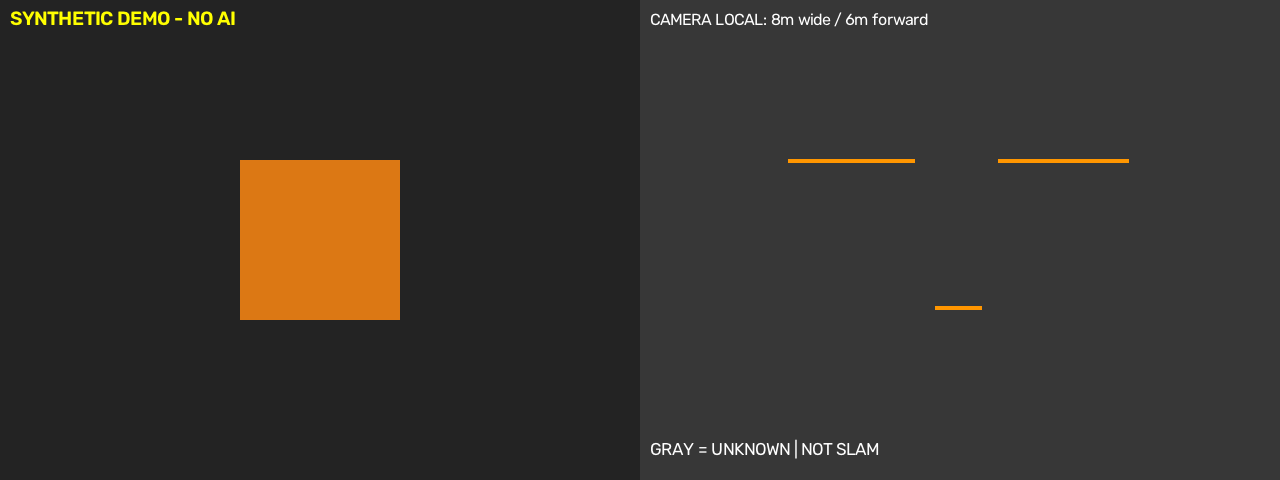

{
  "frames": 35,
  "source": "demo",
  "model": null,
  "median_processing_ms": 3.037015000018073,
  "note": "Host processing time excludes acquisition, output, and display; not mAP or flight validation"
}


In [ ]:
subprocess.run([sys.executable,"-m","unittest","-v"],cwd=ROOT,check=True)
subprocess.run([sys.executable,"app.py","--source","demo","--frames","35","--headless"],cwd=ROOT,check=True)
from IPython.display import display, Image
latest=sorted((ROOT/"runs").iterdir())[-1]
display(Image(filename=str(latest/"dashboard.png")))
print((latest/"summary.json").read_text())

## 실제 5종 데이터·모델 설정
아래 경로를 실제 파일로 바꾸세요. Colab 파일 패널에 업로드하거나, 필요한 경우 별도 셀에서 Google Drive를 마운트한 뒤 경로를 지정합니다. 빈 경로이면 이후 학습·추론 셀은 안내만 출력합니다. 기본 COCO 모델로 재난 5종을 학습했다고 표시하지 않습니다.

데이터 YAML의 경로와 클래스 ID는 실제 YOLO 라벨과 일치해야 합니다. train/val/test는 원본 촬영 장면 단위로 분리하고 증강 이미지가 분할 사이에 섞이지 않게 하세요.

In [ ]:
DATA_YAML = ""  # 예: /content/dataset/data.yaml
WEIGHTS = ""  # 본인의 5종 best.pt. 없다면 아래에서 학습
PREDICT_SOURCE = ""  # 실제 테스트 이미지 또는 영상 경로
RUN_TRAIN = False
EPOCHS = 50
BATCH = 8
from ultralytics import YOLO
import yaml
EXPECTED={"person","fire","smoke","door","staircase"}
def check_names(names):
    names=list(names.values()) if isinstance(names,dict) else list(names)
    assert len(names)==5 and set(names)==EXPECTED, f"5종 클래스 불일치: {names}"
if DATA_YAML:
    assert Path(DATA_YAML).is_file(), "데이터 YAML 없음"
    cfg=yaml.safe_load(Path(DATA_YAML).read_text())
    check_names(cfg["names"])
    print("클래스 확인:",cfg["names"])
else:
    print("실제 학습 대기: 데이터셋 경로를 입력하세요.")

실제 학습 대기: 데이터셋 경로를 입력하세요.


## 실제 데이터 학습
RUN_TRAIN=True와 DATA_YAML을 설정해야 실행됩니다. GPU가 없으면 학습을 중단합니다. runtime 연결 종료 시 /content 파일은 사라질 수 있으므로 모델과 결과를 다운로드하세요.

In [ ]:
if RUN_TRAIN:
    assert DATA_YAML and Path(DATA_YAML).is_file(), "실제 5종 데이터가 필요합니다"
    check_names(yaml.safe_load(Path(DATA_YAML).read_text())["names"])
    assert torch.cuda.is_available(), "학습은 GPU 런타임으로 전환하세요"
    trainer=YOLO("yolov8n.pt")
    trainer.train(data=DATA_YAML,epochs=EPOCHS,batch=BATCH,imgsz=640,device=0,workers=2,seed=42,project=str(ROOT/"training"),name="disaster")
    WEIGHTS=str(trainer.trainer.best)
    print("학습 가중치:",WEIGHTS)
else:
    print("학습 실행 안 함: RUN_TRAIN=False")

학습 실행 안 함: RUN_TRAIN=False


## 실제 모델 평가·추론
평가는 test 분할로 수행합니다. 출력 속도는 Colab GPU 기준이며 Jetson 속도가 아닙니다. 미지정 항목은 실행하지 않습니다.

In [ ]:
if WEIGHTS:
    assert Path(WEIGHTS).is_file(), "가중치 파일 없음"
    detector=YOLO(WEIGHTS)
    check_names(detector.names)
    device=0 if torch.cuda.is_available() else "cpu"
    if DATA_YAML:
        cfg=yaml.safe_load(Path(DATA_YAML).read_text())
        assert cfg.get("test"), "독립된 test 분할을 지정하세요"
        metrics=detector.val(data=DATA_YAML,split="test",imgsz=640,device=device,project=str(ROOT/"evaluation"))
        report={"mAP50":float(metrics.box.map50),"mAP50_95":float(metrics.box.map),"environment":"Colab - not Jetson"}
        (ROOT/"metrics.json").write_text(json.dumps(report,indent=2))
        print(report)
    if PREDICT_SOURCE:
        assert Path(PREDICT_SOURCE).exists(), "테스트 이미지/영상 없음"
        for i,r in enumerate(detector.predict(PREDICT_SOURCE,stream=True,save=True,device=device,project=str(ROOT/"predictions"))):
            if i==0:
                import cv2
                display(Image(data=cv2.imencode(".jpg",r.plot())[1].tobytes()))
else:
    print("실제 추론 대기: 5종 학습 가중치가 필요합니다.")

실제 추론 대기: 5종 학습 가중치가 필요합니다.


## 결과 묶기
파일 패널에서 ZIP을 다운로드할 수 있습니다. 이 ZIP에는 코드와 실행 결과가 들어갑니다. 외부 경로의 기존 가중치는 자동 포함하지 않으므로 별도로 보관하세요.

In [ ]:
import shutil
archive=shutil.make_archive("/content/disaster_drone_colab_result","zip",ROOT)
from IPython.display import FileLink
display(FileLink(archive))
print("결과 ZIP:",archive)

/content/disaster_drone_colab_result.zip

결과 ZIP: /content/disaster_drone_colab_result.zip


In [ ]:
%pip -q install roboflow
from getpass import getpass
from roboflow import Roboflow
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("zeka-s-workspace").project("indoor-elder-objection")
version = project.version(3)
dataset = version.download("yolov8", location="/content/disaster_source")
print("DATASET READY:", dataset.location)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/disaster_source in yolov8:: 100%|██████████| 74425/74425 [00:12<00:00, 5974.84it/s] 


DATASET READY: /content/disaster_source


In [ ]:
import subprocess, sys, json
from pathlib import Path
subprocess.run([sys.executable, "/content/prepare_dataset.py", "--source", "/content/disaster_source", "--out", "/content/disaster_five"], check=True)
DATA_YAML = "/content/disaster_five/data.yaml"
audit = json.loads(Path("/content/disaster_five/audit.json").read_text())
print(json.dumps({k:v for k,v in audit.items() if k != "duplicates"}, indent=2))

{
  "splits": {
    "train": {
      "images": 26033,
      "objects": {
        "person": 14104,
        "fire": 8330,
        "smoke": 10325,
        "door": 1251,
        "staircase": 175
      }
    },
    "valid": {
      "images": 5579,
      "objects": {
        "person": 3049,
        "smoke": 2112,
        "fire": 1768,
        "door": 257,
        "staircase": 38
      }
    },
    "test": {
      "images": 5581,
      "objects": {
        "person": 3441,
        "fire": 1768,
        "smoke": 2245,
        "door": 254,
        "staircase": 31
      }
    }
  },
  "exact_duplicates_removed": 17,
  "source_class_map": {
    "0": "bed",
    "1": "chair",
    "2": "door",
    "3": "fire",
    "4": "fire_extinguisher",
    "5": "knife",
    "6": "person",
    "7": "smoke",
    "8": "sofa",
    "9": "stairs",
    "10": "table",
    "11": "toilet",
    "12": "wardrobe",
    "13": "water_cup",
    "14": "wet_floor",
    "15": "wheelchair"
  },
  "target_names": [
    "person",
    "

In [ ]:
from pathlib import Path
import random, json, yaml, time, shutil
from ultralytics import YOLO
base = Path("/content/disaster_five")
assert (base/"audit.json").is_file(), "Dataset audit must finish successfully first"
quick = Path("/content/disaster_quick")
quick.mkdir(exist_ok=True)
rng = random.Random(42)
for split, per_class, negatives in [("train",200,100),("valid",50,25)]:
    groups = {i:[] for i in range(5)}
    empty = []
    for p in sorted((base/split/"images").iterdir()):
        rows=(base/split/"labels"/(p.stem+".txt")).read_text().splitlines()
        ids={int(row.split()[0]) for row in rows if row.strip()}
        for c in ids: groups[c].append(p)
        if not ids: empty.append(p)
    selected=set()
    for c, items in groups.items():
        assert items, f"Missing class {c} in {split}"
        selected.update(rng.sample(items,min(per_class,len(items))))
    selected.update(rng.sample(empty,min(negatives,len(empty))))
    (quick/(split+".txt")).write_text("\n".join(str(p) for p in sorted(selected))+"\n")
    print(split, len(selected), "images; available class images:", {c:len(v) for c,v in groups.items()}, flush=True)
config={"path":str(quick),"train":str(quick/"train.txt"),"val":str(quick/"valid.txt"),"names":["person","fire","smoke","door","staircase"]}
(quick/"data.yaml").write_text(yaml.safe_dump(config))
started=time.time()
model=YOLO("yolov8n.pt")
model.train(data=str(quick/"data.yaml"),epochs=5,imgsz=640,batch=16,device=0,workers=2,seed=42,project="/content/disaster_drone/training",name="quick_trial",close_mosaic=0,plots=True)
WEIGHTS=str(model.trainer.best)
print("TRIAL COMPLETE. Not final performance:", WEIGHTS, "minutes:", round((time.time()-started)/60,1))
shutil.make_archive("/content/disaster_quick_trial", "zip", model.trainer.save_dir)
print("Saved: /content/disaster_quick_trial.zip")

train 1042 images; available class images: {0: 3440, 1: 7389, 2: 4082, 3: 1138, 4: 149}
valid 256 images; available class images: {0: 748, 1: 1581, 2: 855, 3: 228, 4: 33}
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/disaster_quick/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, l

In [ ]:
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path
import json, shutil, torch, ultralytics
from ultralytics import YOLO
now=datetime.now(ZoneInfo("Asia/Seoul"))
cutoff=now.replace(hour=16,minute=50,second=0,microsecond=0)
budget=(cutoff-now).total_seconds()/3600
assert budget>0.1, "Training cutoff passed; evaluate existing checkpoint instead"
data="/content/disaster_five/data.yaml"
assert Path("/content/disaster_five/audit.json").exists()
print("Training time budget (hours):",round(budget,2),"; then held-out test evaluation",flush=True)
final_model=YOLO("/content/disaster_drone/training/quick_trial/weights/best.pt")
final_model.train(data=data,time=budget,epochs=30,batch=16,imgsz=640,device=0,workers=2,seed=42,optimizer="AdamW",lr0=0.001,patience=12,close_mosaic=5,project="/content/disaster_drone/training",name="deadline_full",plots=True,save=True)
best=Path(final_model.trainer.best)
assert best.is_file()
print("HELD-OUT TEST EVALUATION START",flush=True)
heldout=YOLO(str(best))
metrics=heldout.val(data=data,split="test",imgsz=640,batch=16,device=0,workers=2,plots=True,project="/content/disaster_drone/evaluation",name="deadline_test")
report={"evaluated_at_kst":datetime.now(ZoneInfo("Asia/Seoul")).isoformat(),"environment":"Colab Tesla T4; not Jetson", "weights":str(best),"split":"test","metrics":{k:float(v) for k,v in metrics.results_dict.items()},"per_class":{},"speed_ms":metrics.speed,"torch":torch.__version__,"ultralytics":ultralytics.__version__,"limitations":["Public dataset evaluation, not flight validation","Only pixel-exact duplicate removal; similar-scene leakage not ruled out","Few staircase test instances; inspect class-level metrics"]}
for i,c in enumerate(metrics.box.ap_class_index):
    p,r,ap50,ap=metrics.box.class_result(i)
    report["per_class"][heldout.names[int(c)]]={"precision":float(p),"recall":float(r),"mAP50":float(ap50),"mAP50_95":float(ap)}
out=Path("/content/disaster_final_delivery")
out.mkdir(exist_ok=True)
shutil.copy2(best,out/"best.pt")
shutil.copytree(final_model.trainer.save_dir,out/"training",dirs_exist_ok=True)
shutil.copytree(metrics.save_dir,out/"test_evaluation",dirs_exist_ok=True)
for name in ["audit.json","data.yaml","ATTRIBUTION.txt"]: shutil.copy2(Path("/content/disaster_five")/name,out/name)
(out/"metrics.json").write_text(json.dumps(report,indent=2))
(out/"README.txt").write_text("Colab T4 evaluation of public data. Not Jetson latency or autonomous flight validation. See metrics.json, audit.json and ATTRIBUTION.txt. Test split was not used for model selection.")
zip_path=shutil.make_archive("/content/disaster_final_delivery","zip",out)
print(json.dumps(report,indent=2))
print("FINAL DELIVERY READY:",zip_path,flush=True)

Training time budget (hours): 2.43 ; then held-out test evaluation
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/disaster_five/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/disaster_drone/training/quick